# EV Highway Corridor Reliability Gap Analysis

#### This project analyzes electric vehicle (EV) adoption and fast-charging infrastructure availability across Indian states and six major national highways. Using EV registration data, charging-station information, state boundaries, and highway geographical data, the project identifies charging coverage gaps and highlights regions that may require improved infrastructure. Python-based data analysis, geospatial techniques, and visualizations are used to evaluate charging accessibility and support data-driven EV infrastructure planning.

In [2]:
import sys
print(sys.executable)

c:\Users\INBA\Desktop\OneDrive - ELCOT\Inba\Anudip\Project\EV_Highway_Corridor_Reliability_Gap_Analysis\.venv\Scripts\python.exe


In [3]:
import requests
import numpy as np
import pandas as pd
import json
import geopandas as gpd
import warnings
import os
from shapely.ops import unary_union, linemerge, substring
import matplotlib.pyplot as plt
from itertools import combinations
from shapely import wkb
from shapely.geometry import MultiPolygon
from shapely.geometry.base import BaseGeometry
from shapely.validation import make_valid
from pathlib import Path
import matplotlib.colors as mcolors
import seaborn as sns


# Used to create custom legends for maps
from matplotlib.lines import Line2D

# Used for statistical plots and styling
import seaborn as sns

# Used for fast nearest-neighbour distance calculations
from scipy.spatial import cKDTree

# Used for merging and splitting highway geometries
from shapely.ops import unary_union, linemerge, substring

# Used for state-level clustering
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler


# EV Registration

In [4]:
# Imports and load raw data
df = pd.read_csv("../Dataset/Raw datasets/All_type_of_EV_registration.csv")

print("Chargers shape:", df.shape)
df.head(37)

Chargers shape: (37, 12)


,"EV Type (ELECTRIC(BOV), PURE EV) Wise State Wise and Calendar Year Data for AN, AP, AR, AS, BR, CH, CG, DL, GA, GJ, HR, HP, JK, JH, KA, KL, LA, LD, MP, MH, MN, ML, MZ, NL, OR, PY, PB, RJ, SK, TN, TG, TR, DD, UP, UK, WB (2017-2026)\n\nState",2017,2018,2019,2020,2021,2022,2023,2024,2025,2026,Total
0,Andaman & Nicobar Island,0,20,2,36,92,23,26,64,166,117,546
1,Andhra Pradesh,1,1180,2155,1650,9681,29357,32876,56492,59842,85267,278501
2,Arunachal Pradesh,0,1,1,4,2,2,18,47,103,136,314
3,Assam,3831,7398,10859,8357,15633,40697,60786,68130,85142,83467,384300
4,Bihar,3594,8464,12380,12446,23083,55755,88223,112856,123797,119840,560438
5,Chandigarh,23,213,508,369,729,2720,6390,6182,5180,5105,27419
6,Chhattisgarh,944,1903,2744,1489,4216,22361,38245,48859,47735,48029,216525
7,Delhi,17846,20902,23221,12374,25792,62225,73721,80388,113758,85670,515897
8,Goa,36,25,42,82,1100,5687,9485,11491,9367,9865,47180
9,Gujarat,173,500,947,1124,9761,68994,88617,75759,75779,94188,415842


In [5]:
# Create a working copy

ev_df = df.copy()

print("Original shape:", df.shape)
print("Working copy shape:", ev_df.shape)

Original shape: (37, 12)
Working copy shape: (37, 12)


In [6]:
# Check column names

print(ev_df.columns.tolist())

['EV Type (ELECTRIC(BOV), PURE EV) Wise State Wise and Calendar Year Data for AN, AP, AR, AS, BR, CH, CG, DL, GA, GJ, HR, HP, JK, JH, KA, KL, LA, LD, MP, MH, MN, ML, MZ, NL, OR, PY, PB, RJ, SK, TN, TG, TR, DD, UP, UK, WB (2017-2026)\\n\\nState', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025', '2026', 'Total']


In [7]:
# CELL 4: Rename the state column

ev_df = ev_df.rename(columns={
    ev_df.columns[0]: "State"
})

print(ev_df.columns.tolist())

['State', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025', '2026', 'Total']


In [8]:
# Check State values

print(ev_df["State"].tolist())

['Andaman & Nicobar Island', 'Andhra Pradesh', 'Arunachal Pradesh', 'Assam', 'Bihar', 'Chandigarh', 'Chhattisgarh', 'Delhi', 'Goa', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu and Kashmir', 'Jharkhand', 'Karnataka', 'Kerala', 'Ladakh', 'Lakshadweep', 'Madhya Pradesh', 'Maharashtra', 'Manipur', 'Meghalaya', 'Mizoram', 'Nagaland', 'Odisha', 'Puducherry', 'Punjab', 'Rajasthan', 'Sikkim', 'Tamil Nadu', 'Telangana', 'Tripura', 'UT of DNH and DD', 'Uttar Pradesh', 'Uttarakhand', 'West Bengal', 'Total']


In [9]:
# Remove Total row

ev_df = ev_df[ev_df["State"] != "Total"].copy()

print("Shape after removing Total row:", ev_df.shape)
ev_df["State"].tail()

Shape after removing Total row: (36, 12)


31             Tripura
32    UT of DNH and DD
33       Uttar Pradesh
34         Uttarakhand
35         West Bengal
Name: State, dtype: str

In [10]:
# Check duplicate states

print("Duplicate state names:", ev_df["State"].duplicated().sum())

print("\nDuplicate states:")
print(ev_df[ev_df["State"].duplicated(keep=False)]["State"])

Duplicate state names: 0

Duplicate states:
Series([], Name: State, dtype: str)


In [11]:
# Check missing values

print(ev_df.isnull().sum())

State    0
2017     0
2018     0
2019     0
2020     0
2021     0
2022     0
2023     0
2024     0
2025     0
2026     0
Total    0
dtype: int64


In [12]:
# Check data types

print(ev_df.dtypes)

State      str
2017     int64
2018     int64
2019     int64
2020     int64
2021     int64
2022     int64
2023     int64
2024     int64
2025     int64
2026     int64
Total    int64
dtype: object


In [13]:
# Check for negative values

numeric_cols = ev_df.columns[1:]

print((ev_df[numeric_cols] < 0).sum())

2017     0
2018     0
2019     0
2020     0
2021     0
2022     0
2023     0
2024     0
2025     0
2026     0
Total    0
dtype: int64


In [14]:
# Validate Total column

year_cols = [str(year) for year in range(2017, 2027)]

calculated_total = ev_df[year_cols].sum(axis=1)

print("Rows where Total does not match calculated total:",
      (ev_df["Total"] != calculated_total).sum())

Rows where Total does not match calculated total: 0


In [15]:
# Check duplicate rows

print("Duplicate rows:", ev_df.duplicated().sum())

Duplicate rows: 0


In [16]:
# Check whitespace in State names

print(
    "States with leading/trailing whitespace:",
    (~ev_df["State"].eq(ev_df["State"].str.strip())).sum()
)

States with leading/trailing whitespace: 0


In [17]:
# Check blank State values

print(
    "Blank State values:",
    ev_df["State"].str.strip().eq("").sum()
)

Blank State values: 0


In [18]:
# Check zero values

print((ev_df[year_cols] == 0).sum())

2017    9
2018    4
2019    1
2020    2
2021    1
2022    1
2023    1
2024    0
2025    0
2026    0
dtype: int64


In [19]:
# Identify zero registration values

zero_check = ev_df[year_cols].eq(0)

display(ev_df.loc[zero_check.any(axis=1), ["State"] + year_cols].reset_index(drop=True))

,State,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
0,Andaman & Nicobar Island,0,20,2,36,92,23,26,64,166,117
1,Arunachal Pradesh,0,1,1,4,2,2,18,47,103,136
2,Jammu and Kashmir,0,90,75,74,1147,4690,9752,13212,11827,13348
3,Ladakh,0,0,1,0,6,40,28,18,3,8
4,Lakshadweep,0,0,1,7,5,2,9,15,32,73
5,Meghalaya,0,2,13,3,5,41,115,798,945,700
6,Mizoram,0,0,1,1,1,36,168,560,825,1032
7,Nagaland,0,1,31,12,2,3,6,13,23,25
8,Sikkim,0,0,0,0,0,0,0,7,9,13


In [20]:
# Check duplicate column names

print("Duplicate column names:", ev_df.columns.duplicated().sum())

Duplicate column names: 0


In [21]:
# Check unique state count

print("Number of states/UTs:", ev_df["State"].nunique())

Number of states/UTs: 36


In [22]:
ev_df.describe()

,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026,Total
count,36.000000,36.000000,36.000000,36.000000,36.000000,36.000000,36.000000,36.000000,36.000000,36.000000,3.600000e+01
mean,2422.916667,3642.083333,4665.166667,3499.361111,9477.444444,29429.583333,43964.888889,56285.416667,65468.722222,69417.194444,2.882728e+05
std,7274.896564,9377.834829,10093.569553,6036.636922,13956.920175,39576.280703,61199.329325,77784.073867,87882.861634,87779.446377,3.884789e+05
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.000000,3.000000,8.000000,2.900000e+01
25%,0.750000,23.750000,39.250000,64.500000,108.500000,291.250000,341.250000,738.500000,1135.500000,1190.250000,3.742250e+03
50%,75.500000,432.500000,997.500000,1223.500000,4433.000000,13868.500000,21275.500000,34492.000000,35709.500000,32570.000000,1.608890e+05
75%,1367.000000,3212.000000,5284.500000,3967.500000,9932.250000,39908.000000,69412.250000,76916.250000,102453.250000,115330.750000,4.202545e+05
max,40645.000000,53199.000000,55786.000000,31256.000000,66688.000000,162879.000000,278296.000000,369283.000000,405364.000000,352096.000000,1.815492e+06


In [23]:
# Save cleaned dataset

clean_path = "../Dataset/Cleaned datasets/EV_registration_cleaned.csv"

ev_df.to_csv(clean_path, index=False)

print("Clean dataset saved successfully.")
print("Shape:", ev_df.shape)

Clean dataset saved successfully.
Shape: (36, 12)


In [24]:
ev_df.head()

,State,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026,Total
0,Andaman & Nicobar Island,0,20,2,36,92,23,26,64,166,117,546
1,Andhra Pradesh,1,1180,2155,1650,9681,29357,32876,56492,59842,85267,278501
2,Arunachal Pradesh,0,1,1,4,2,2,18,47,103,136,314
3,Assam,3831,7398,10859,8357,15633,40697,60786,68130,85142,83467,384300
4,Bihar,3594,8464,12380,12446,23083,55755,88223,112856,123797,119840,560438


# EV Charging Station

In [25]:
# Open Charge Map API key
API_KEY = "f82b0388-2e7e-4d18-8207-6fe535c64cb8"

# Open Charge Map API endpoint for charging-station data
url = "https://api.openchargemap.io/v3/poi/"

# Parameters used to request charging stations located in India
params = {
    "output": "json",
    "countrycode": "IN",
    "maxresults": 5000,
    "compact": False,
    "verbose": False,
    "key": API_KEY
}

# Send the request to the Open Charge Map API
response = requests.get(url, params=params)
print("Status code:", response.status_code)

Status code: 200


In [26]:
# Convert the API response from JSON format into Python objects
data = response.json()

# Check how many charging-station records were retrieved
print("Number of charging stations pulled:", len(data))

Number of charging stations pulled: 1980


In [27]:
# Inspect one raw API record to understand its nested structure
data[0]

{'DataProvider': {'WebsiteURL': 'http://openchargemap.org',
  'DataProviderStatusType': {'IsProviderEnabled': True,
   'ID': 1,
   'Title': 'Manual Data Entry'},
  'IsRestrictedEdit': False,
  'IsOpenDataLicensed': True,
  'IsApprovedImport': True,
  'License': 'Licensed under Creative Commons Attribution 4.0 International (CC BY 4.0)',
  'ID': 1,
  'Title': 'Open Charge Map Contributors'},
 'OperatorInfo': {'ID': 1, 'Title': '(Unknown Operator)'},
 'UsageType': {'ID': 1, 'Title': 'Public'},
 'StatusType': {'IsOperational': True,
  'IsUserSelectable': True,
  'ID': 50,
  'Title': 'Operational'},
 'SubmissionStatus': {'IsLive': True,
  'ID': 200,
  'Title': 'Submission Published'},
 'IsRecentlyVerified': True,
 'DateLastVerified': '2026-10-10T17:44:00Z',
 'ID': 511406,
 'UUID': '1C7915CA-2296-41F2-B055-8ED5F1F5E12C',
 'DataProviderID': 1,
 'OperatorID': 1,
 'UsageTypeID': 1,
 'AddressInfo': {'ID': 511795,
  'Title': 'khuurampur',
  'AddressLine1': 'KHURRAMPUR MURADNAGAR GHAZIABAD',
  'A

In [28]:
# Flatten everything except Connections automatically
df_chargers = pd.json_normalize(data)

# Check the number of rows and columns after flattening
print("Shape after normalize:", df_chargers.shape)

# Display all available columns so we can decide
# which fields are useful for the project
print("\nAll column names:")
print(df_chargers.columns.tolist())

Shape after normalize: (1980, 72)

All column names:
['IsRecentlyVerified', 'DateLastVerified', 'ID', 'UUID', 'DataProviderID', 'OperatorID', 'UsageTypeID', 'Connections', 'NumberOfPoints', 'StatusTypeID', 'DateLastStatusUpdate', 'DataQualityLevel', 'DateCreated', 'SubmissionStatusTypeID', 'DataProvider.WebsiteURL', 'DataProvider.DataProviderStatusType.IsProviderEnabled', 'DataProvider.DataProviderStatusType.ID', 'DataProvider.DataProviderStatusType.Title', 'DataProvider.IsRestrictedEdit', 'DataProvider.IsOpenDataLicensed', 'DataProvider.IsApprovedImport', 'DataProvider.License', 'DataProvider.ID', 'DataProvider.Title', 'OperatorInfo.ID', 'OperatorInfo.Title', 'UsageType.ID', 'UsageType.Title', 'StatusType.IsOperational', 'StatusType.IsUserSelectable', 'StatusType.ID', 'StatusType.Title', 'SubmissionStatus.IsLive', 'SubmissionStatus.ID', 'SubmissionStatus.Title', 'AddressInfo.ID', 'AddressInfo.Title', 'AddressInfo.AddressLine1', 'AddressInfo.AddressLine2', 'AddressInfo.Town', 'AddressI

In [29]:
# Rename long API column names into shorter and easier-to-use names for the cleaning and analysis stages.
df_chargers = df_chargers.rename(columns={
    "AddressInfo.Title": "name",
    "AddressInfo.Latitude": "latitude",
    "AddressInfo.Longitude": "longitude",
    "AddressInfo.Town": "town",
    "AddressInfo.StateOrProvince": "state",
    "AddressInfo.Postcode": "postcode",
    "OperatorInfo.Title": "operator",
    "StatusType.Title": "status",
    "StatusType.IsOperational": "is_operational",
    "DateCreated": "date_created",
    "DateLastVerified": "date_last_verified"
})

In [30]:
# Find the highest charging power available at each station.
def get_max_power(connections):
    # Return None when connection information is missing
    if not connections or not isinstance(connections, list):
        return None

    # Collect valid PowerKW values from all connectors
    powers = [
        c.get("PowerKW")
        for c in connections
        if c.get("PowerKW")
    ]

    # Return the highest power value available
    return max(powers) if powers else None


In [31]:
# Calculate the total number of charging points
# represented by all connections at a station.
def get_total_points(connections):
    # Return 0 when connection information is unavailable
    if not connections or not isinstance(connections, list):
        return 0

    # Sum the Quantity value from each connection.
    # If Quantity is missing, assume one charging point.
    return sum(c.get("Quantity", 1) or 1 for c in connections)


In [32]:
# Check whether at least one connection supports
# fast charging.
def has_fast_charging(connections):
    # Return False when no connection information exists
    if not connections or not isinstance(connections, list):
        return False

    # Return True if any connection is identified
    # as fast-charge capable
    return any(
        c.get("Level", {}).get("IsFastChargeCapable", False)
        for c in connections
    )

In [33]:
# Apply the functions to the nested Connections column
df_chargers["max_power_kw"] = (
    df_chargers["Connections"].apply(get_max_power)
)

df_chargers["total_points"] = (
    df_chargers["Connections"].apply(get_total_points)
)

df_chargers["has_fast_charging"] = (
    df_chargers["Connections"].apply(has_fast_charging)
)

In [34]:
# Keep only the fields required for the EV charging
# infrastructure analysis.
data = df_chargers[[
    "ID",
    "name",
    "latitude",
    "longitude",
    "town",
    "state",
    "postcode",
    "operator",
    "status",
    "is_operational",
    "max_power_kw",
    "total_points",
    "has_fast_charging",
    "date_created",
    "date_last_verified"
]]

# Confirm the final raw dataset structure
print("Final shape:", data.shape)

# Display the first few records for verification
data.head(10)

Final shape: (1980, 15)


,ID,name,latitude,longitude,town,state,postcode,operator,status,is_operational,max_power_kw,total_points,has_fast_charging,date_created,date_last_verified
0,511406,khuurampur,28.790915,77.474036,Muradnagar,Uttar Pradesh,201206,(Unknown Operator),Operational,True,3.3,1,False,2026-10-07T17:43:00Z,2026-10-10T17:44:00Z
1,510840,E-Fill Electric Hotel Food Mania,31.602844,76.924626,"Balh, Mandi",Himachal Pradesh,175021,E-Fill Electric (IN),Operational,True,30.0,1,True,2026-09-30T16:02:00Z,2026-10-03T16:15:00Z
2,510821,Nilkanth EV Charging Station - ChargeJet,23.759334,53.322467,Ahmedabad,Gujarat,382445,(Unknown Operator),Operational,True,160.0,3,True,2026-09-30T04:52:00Z,2026-10-03T04:57:00Z
3,510820,Nilkanth EV Charging Station - ChargeJet,22.979910,72.633820,Ahemdabad,Gujarat,382445,(Unknown Operator),Operational,True,158.0,4,True,2026-09-30T04:24:00Z,2026-10-03T04:26:00Z
4,510563,bhanu prasad hostal,16.258243,80.323226,Guntar,Andhra Pradesh,534350,(Unknown Operator),Operational,True,120.0,1,True,2026-09-26T04:27:00Z,2026-09-29T04:31:00Z
5,510426,SALZER DEVELOPMENT,19.105321,72.875887,,NaN,,Salzer NexCharge (IN),Not Operational,False,7.0,1,False,2026-09-23T16:17:00Z,2026-10-13T04:16:00Z
6,510425,Salzer Panel Test Charger 1,11.929501,76.937771,,NaN,,Salzer NexCharge (IN),Not Operational,False,30.0,2,True,2026-09-23T16:17:00Z,2026-10-13T04:16:00Z
7,510424,7.4 kW - New Model Testing,11.163261,76.934373,,NaN,,Salzer NexCharge (IN),Not Operational,False,7.0,1,False,2026-09-23T16:17:00Z,2026-10-13T04:16:00Z
8,510423,Salzer Test Charger,10.589207,79.589475,,NaN,,Salzer NexCharge (IN),Not Operational,False,22.0,1,False,2026-09-23T16:17:00Z,2026-10-13T04:16:00Z
9,510422,Salzer Panel Test Charger 2,10.585263,77.253175,,NaN,,Salzer NexCharge (IN),Not Operational,False,30.0,2,True,2026-09-23T16:17:00Z,2026-10-13T04:16:00Z


In [35]:
# Save the API output after basic extraction to the Raw datasets folder.

data.to_csv(
    "../Dataset/Raw datasets/ev_charging_stations.csv",
    index=False
)

print("Saved successfully! Check your /data folder.")

Saved successfully! Check your /data folder.


In [36]:
# Load the raw charging-station dataset collected from Open Charge Map.
df_chargers = pd.read_csv("../Dataset/Raw datasets/ev_charging_stations.csv")

print("Chargers shape:", df_chargers.shape)
df_chargers.head()

Chargers shape: (1980, 15)


,ID,name,latitude,longitude,town,state,postcode,operator,status,is_operational,max_power_kw,total_points,has_fast_charging,date_created,date_last_verified
0,511406,khuurampur,28.790915,77.474036,Muradnagar,Uttar Pradesh,201206,(Unknown Operator),Operational,True,3.3,1,False,2026-10-07T17:43:00Z,2026-10-10T17:44:00Z
1,510840,E-Fill Electric Hotel Food Mania,31.602844,76.924626,"Balh, Mandi",Himachal Pradesh,175021,E-Fill Electric (IN),Operational,True,30.0,1,True,2026-09-30T16:02:00Z,2026-10-03T16:15:00Z
2,510821,Nilkanth EV Charging Station - ChargeJet,23.759334,53.322467,Ahmedabad,Gujarat,382445,(Unknown Operator),Operational,True,160.0,3,True,2026-09-30T04:52:00Z,2026-10-03T04:57:00Z
3,510820,Nilkanth EV Charging Station - ChargeJet,22.979910,72.633820,Ahemdabad,Gujarat,382445,(Unknown Operator),Operational,True,158.0,4,True,2026-09-30T04:24:00Z,2026-10-03T04:26:00Z
4,510563,bhanu prasad hostal,16.258243,80.323226,Guntar,Andhra Pradesh,534350,(Unknown Operator),Operational,True,120.0,1,True,2026-09-26T04:27:00Z,2026-09-29T04:31:00Z


In [37]:
print("Column data types:")
print(df_chargers.dtypes)

print("\nMissing values per column:")
print(df_chargers.isnull().sum())

print("\nTotal duplicate rows (exact full-row duplicates):")
print(df_chargers.duplicated().sum())

Column data types:
ID                      int64
name                      str
latitude              float64
longitude             float64
town                      str
state                     str
postcode                  str
operator                  str
status                    str
is_operational           bool
max_power_kw          float64
total_points            int64
has_fast_charging        bool
date_created              str
date_last_verified        str
dtype: object

Missing values per column:
ID                      0
name                    0
latitude                0
longitude               0
town                  441
state                  36
postcode              473
operator              390
status                  0
is_operational          0
max_power_kw          108
total_points            0
has_fast_charging       0
date_created            0
date_last_verified      0
dtype: int64

Total duplicate rows (exact full-row duplicates):
0


In [38]:
df_chargers.info()

<class 'pandas.DataFrame'>
RangeIndex: 1980 entries, 0 to 1979
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  1980 non-null   int64  
 1   name                1980 non-null   str    
 2   latitude            1980 non-null   float64
 3   longitude           1980 non-null   float64
 4   town                1539 non-null   str    
 5   state               1944 non-null   str    
 6   postcode            1507 non-null   str    
 7   operator            1590 non-null   str    
 8   status              1980 non-null   str    
 9   is_operational      1980 non-null   bool   
 10  max_power_kw        1872 non-null   float64
 11  total_points        1980 non-null   int64  
 12  has_fast_charging   1980 non-null   bool   
 13  date_created        1980 non-null   str    
 14  date_last_verified  1980 non-null   str    
dtypes: bool(2), float64(3), int64(2), str(8)
memory usage: 412.0 KB


In [39]:
print("Unique state values BEFORE cleaning:")
print(sorted(df_chargers["state"].dropna().unique()))

Unique state values BEFORE cleaning:
[' Tamil Nadu', 'Ahmedabad', 'Andhra Pradesh', 'Assam', 'Bangalore Urban', 'Bihar', 'Burari', 'Dadra and Nagar Haveli', 'Delhi', 'Delhi ', 'GJ', 'Goa', 'Gujarat', 'Gujarat ', 'Haryana', 'Haryana ', 'Himachal Pradesh', 'India', 'Jammu and Kashmir', 'Jharkhand', 'KA', 'KARNATAKA', 'Karnatak', 'Karnataka', 'Karnataka ', 'Keraka', 'Keral', 'Kerala', 'Kerala ', 'Lerala', 'MH', 'MP', 'Madhya Pradesh', 'Maharashtra', 'Maharashtra ', 'Maharshtra', 'Mahrashtra', 'New Dehi', 'Odisha', 'Puducherry', 'Punjab ', 'RJ', 'Rajasthan', 'Rajasthan ', 'TAMILNADU', 'Tamil Nadu', 'Tamil Nadu ', 'Tamil Nasdu', 'Tamil nadu', 'TamilNadu', 'Tamilnadu', 'Tamilnadu ', 'Telangana', 'Telangana ', 'UTTAR PRADESH', 'UTTAR PRADESH ', 'Uttar Pradesh', 'Uttar Pradesh ', 'Uttarakhand', 'Uttarakhnad', 'Villupuram', 'West Bengal', 'chennai', 'karnataka', 'rajasthan', 'uttar pradesh ', 'west bengal']


In [40]:
# Remove leading and trailing spaces from state names.
df_chargers["state"] = (
    df_chargers["state"]
    .astype(str)
    .str.strip()
)

In [41]:
# Remove leading and trailing spaces from state names.
df_chargers["state"] = (
    df_chargers["state"]
    .astype(str)
    .str.strip()
)


# Mapping used to correct common spelling variations,
# abbreviations and incorrectly entered locations.
state_name_map = {

    # Different spellings/capitalization
    "KARNATAKA": "Karnataka",
    "karnataka": "Karnataka",
    "Karnatak": "Karnataka",

    "TAMILNADU": "Tamil Nadu",
    "TamilNadu": "Tamil Nadu",
    "Tamilnadu": "Tamil Nadu",
    "Tamil nadu": "Tamil Nadu",

    "UTTAR PRADESH": "Uttar Pradesh",
    "uttar pradesh": "Uttar Pradesh",

    "rajasthan": "Rajasthan",
    "west bengal": "West Bengal",

    # State abbreviations
    "GJ": "Gujarat",
    "KA": "Karnataka",
    "MH": "Maharashtra",
    "MP": "Madhya Pradesh",
    "RJ": "Rajasthan",

    # Spelling errors
    "Maharshtra": "Maharashtra",
    "Mahrashtra": "Maharashtra",
    "Keraka": "Kerala",
    "Keral": "Kerala",
    "Lerala": "Kerala",
    "Tamil Nasdu": "Tamil Nadu",
    "Uttarakhnad": "Uttarakhand",
    "New Dehi": "Delhi",

    # Cities/districts incorrectly entered in the state field
    "Ahmedabad": "Gujarat",
    "Bangalore Urban": "Karnataka",
    "Burari": "Delhi",
    "Villupuram": "Tamil Nadu",
    "chennai": "Tamil Nadu",

    # Invalid country-level entry
    "India": None
}


# Apply the state-name corrections
df_chargers["state"] = (
    df_chargers["state"].replace(state_name_map)
)

# Display the result after applying the mapping
df_chargers

,ID,name,latitude,longitude,town,state,postcode,operator,status,is_operational,max_power_kw,total_points,has_fast_charging,date_created,date_last_verified
0,511406,khuurampur,28.790915,77.474036,Muradnagar,Uttar Pradesh,201206,(Unknown Operator),Operational,True,3.3,1,False,2026-10-07T17:43:00Z,2026-10-10T17:44:00Z
1,510840,E-Fill Electric Hotel Food Mania,31.602844,76.924626,"Balh, Mandi",Himachal Pradesh,175021,E-Fill Electric (IN),Operational,True,30.0,1,True,2026-09-30T16:02:00Z,2026-10-03T16:15:00Z
2,510821,Nilkanth EV Charging Station - ChargeJet,23.759334,53.322467,Ahmedabad,Gujarat,382445,(Unknown Operator),Operational,True,160.0,3,True,2026-09-30T04:52:00Z,2026-10-03T04:57:00Z
3,510820,Nilkanth EV Charging Station - ChargeJet,22.979910,72.633820,Ahemdabad,Gujarat,382445,(Unknown Operator),Operational,True,158.0,4,True,2026-09-30T04:24:00Z,2026-10-03T04:26:00Z
4,510563,bhanu prasad hostal,16.258243,80.323226,Guntar,Andhra Pradesh,534350,(Unknown Operator),Operational,True,120.0,1,True,2026-09-26T04:27:00Z,2026-09-29T04:31:00Z
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1975,103604,"International Tech Park, Bangalore",12.985421,77.738513,Bangalore,Karnataka,560066,(Unknown Operator),Operational,True,3.0,2,False,2018-05-04T08:06:00Z,2018-05-11T11:06:00Z
1976,103603,Ather Grid Point - Ascendas Park square mall,12.987219,77.736474,Bangalore,Karnataka,560066,(Unknown Operator),Operational,True,3.0,2,False,2018-05-04T08:01:00Z,2018-05-11T11:06:00Z
1977,96047,Tellus Power,17.413362,78.426597,Hyderabad,Telangana,500034,NaN,Operational,True,7.2,1,False,2017-12-07T10:12:00Z,2017-12-08T08:52:00Z
1978,92772,Tata Power Receiving Station,19.095796,72.926011,Mumbai,NaN,400077,(Business Owner at Location),Operational,True,NaN,3,False,2017-09-10T11:59:00Z,2017-09-10T11:59:00Z


In [42]:
# Convert state names to title case so that remaining
# capitalization differences are standardized.
df_chargers["state"] = (
    df_chargers["state"]
    .astype(str)
    .str.strip()
    .str.title()
)


In [43]:
# Convert string representations of missing values back
# into actual missing values.
df_chargers["state"] = df_chargers["state"].replace({
    "None": None,
    "Nan": None
})

# Display the cleaned dataset for verification
df_chargers

,ID,name,latitude,longitude,town,state,postcode,operator,status,is_operational,max_power_kw,total_points,has_fast_charging,date_created,date_last_verified
0,511406,khuurampur,28.790915,77.474036,Muradnagar,Uttar Pradesh,201206,(Unknown Operator),Operational,True,3.3,1,False,2026-10-07T17:43:00Z,2026-10-10T17:44:00Z
1,510840,E-Fill Electric Hotel Food Mania,31.602844,76.924626,"Balh, Mandi",Himachal Pradesh,175021,E-Fill Electric (IN),Operational,True,30.0,1,True,2026-09-30T16:02:00Z,2026-10-03T16:15:00Z
2,510821,Nilkanth EV Charging Station - ChargeJet,23.759334,53.322467,Ahmedabad,Gujarat,382445,(Unknown Operator),Operational,True,160.0,3,True,2026-09-30T04:52:00Z,2026-10-03T04:57:00Z
3,510820,Nilkanth EV Charging Station - ChargeJet,22.979910,72.633820,Ahemdabad,Gujarat,382445,(Unknown Operator),Operational,True,158.0,4,True,2026-09-30T04:24:00Z,2026-10-03T04:26:00Z
4,510563,bhanu prasad hostal,16.258243,80.323226,Guntar,Andhra Pradesh,534350,(Unknown Operator),Operational,True,120.0,1,True,2026-09-26T04:27:00Z,2026-09-29T04:31:00Z
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1975,103604,"International Tech Park, Bangalore",12.985421,77.738513,Bangalore,Karnataka,560066,(Unknown Operator),Operational,True,3.0,2,False,2018-05-04T08:06:00Z,2018-05-11T11:06:00Z
1976,103603,Ather Grid Point - Ascendas Park square mall,12.987219,77.736474,Bangalore,Karnataka,560066,(Unknown Operator),Operational,True,3.0,2,False,2018-05-04T08:01:00Z,2018-05-11T11:06:00Z
1977,96047,Tellus Power,17.413362,78.426597,Hyderabad,Telangana,500034,NaN,Operational,True,7.2,1,False,2017-12-07T10:12:00Z,2017-12-08T08:52:00Z
1978,92772,Tata Power Receiving Station,19.095796,72.926011,Mumbai,NaN,400077,(Business Owner at Location),Operational,True,NaN,3,False,2017-09-10T11:59:00Z,2017-09-10T11:59:00Z


In [44]:
# Count records before removing invalid states
before = df_chargers.shape[0]

# Remove records where the state could not be identified.
# State is important for state-level charging infrastructure analysis, so records without a valid state are excluded.
df_chargers = df_chargers.dropna(subset=["state"])

# Count records after cleaning
after = df_chargers.shape[0]

print(
    f"Dropped {before - after} rows with invalid/missing state. "
    f"Remaining: {after}"
)

Dropped 37 rows with invalid/missing state. Remaining: 1943


In [45]:
# Check the final list of state names after cleaning.
print("\nUnique state values AFTER cleaning:")
print(sorted(df_chargers["state"].unique()))


Unique state values AFTER cleaning:
['Andhra Pradesh', 'Assam', 'Bihar', 'Dadra And Nagar Haveli', 'Delhi', 'Goa', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu And Kashmir', 'Jharkhand', 'Karnataka', 'Kerala', 'Madhya Pradesh', 'Maharashtra', 'Odisha', 'Puducherry', 'Punjab', 'Rajasthan', 'Tamil Nadu', 'Telangana', 'Uttar Pradesh', 'Uttarakhand', 'West Bengal']


In [46]:
# Town is not required for the geographic analysis because latitude and longitude are available.
# Therefore, missing town names are labelled as Unknown.
df_chargers["town"] = (
    df_chargers["town"].fillna("Unknown")
)

In [47]:
# State should already have been cleaned and records with missing states removed above.
# Fill any remaining missing value defensively.
df_chargers["state"] = (
    df_chargers["state"].fillna("Unknown")
)

In [48]:
# Postcode is not required for spatial analysis because geographic coordinates are available.
df_chargers["postcode"] = (
    df_chargers["postcode"].fillna("Unknown")
)

In [49]:
# Operator information is not available for some crowd-sourced charging stations.
df_chargers["operator"] = (
    df_chargers["operator"].fillna("Unknown Operator")
)

In [50]:
# Missing power values are replaced with 0 to retain the station location instead of removing the entire record.
df_chargers["max_power_kw"] = (
    df_chargers["max_power_kw"].fillna(0)
)

In [51]:
# Verify the missing-value treatment
print("Missing values after fill:")
print(df_chargers.isnull().sum())

Missing values after fill:
ID                    0
name                  0
latitude              0
longitude             0
town                  0
state                 0
postcode              0
operator              0
status                0
is_operational        0
max_power_kw          0
total_points          0
has_fast_charging     0
date_created          0
date_last_verified    0
dtype: int64


In [52]:
# Check the minimum and maximum charging power values.
# Extremely large values may indicate data-entry errors.
print(
    "Power range:",
    df_chargers["max_power_kw"].min(),
    "to",
    df_chargers["max_power_kw"].max()
)


Power range: 0.0 to 1000000.0


In [53]:
# Remove records with charging power above 500 kW.
# Such values are treated as unrealistic/outliers for
# this dataset and are excluded from the analysis.
before = df_chargers.shape[0]

df_chargers = df_chargers[
    df_chargers["max_power_kw"] <= 500
]

after = df_chargers.shape[0]

print(
    f"Removed {before - after} rows with unrealistic power values."
)

Removed 2 rows with unrealistic power values.


In [54]:
# Count records before duplicate-location removal
before = df_chargers.shape[0]

# Remove exact duplicate geographic locations.
# Latitude and longitude are used because the analysis
# focuses on the physical location of charging infrastructure.
df_chargers = df_chargers.drop_duplicates(
    subset=["latitude", "longitude"]
)

In [55]:
# Count records after duplicate removal
after = df_chargers.shape[0]

print(
    f"Removed {before - after} duplicate-location stations. "
    f"Remaining: {after}"
)

Removed 97 duplicate-location stations. Remaining: 1844


In [56]:
# Ensure latitude and longitude are numeric
df_chargers["latitude"] = pd.to_numeric(
    df_chargers["latitude"], errors="coerce"
)

df_chargers["longitude"] = pd.to_numeric(
    df_chargers["longitude"], errors="coerce"
)

# Find missing or invalid geographic coordinates
invalid_coords = df_chargers[
    df_chargers["latitude"].isna()
    | df_chargers["longitude"].isna()
    | ~df_chargers["latitude"].between(6, 38)
    | ~df_chargers["longitude"].between(68, 98)
]

print("Invalid coordinate records:", len(invalid_coords))

display(
    invalid_coords[
        ["ID", "name", "latitude", "longitude", "town", "state"]
    ]
)


Invalid coordinate records: 2


,ID,name,latitude,longitude,town,state
2,510821,Nilkanth EV Charging Station - ChargeJet,23.759334,53.322467,Ahmedabad,Gujarat
1894,301542,Ero G Electric Charging Station,9.357268,11.301994,Erode,Tamil Nadu


In [57]:
# These two IDs were identified in the current notebook output.
# Their coordinates conflict with their listed Indian locations.
# Recheck the source records before excluding them.

confirmed_invalid_ids = [510821, 301542]

df_chargers = df_chargers[
    ~df_chargers["ID"].isin(confirmed_invalid_ids)
].copy()

print("Shape after coordinate cleaning:", df_chargers.shape)

# Validate again
remaining_invalid_coords = df_chargers[
    df_chargers["latitude"].isna()
    | df_chargers["longitude"].isna()
    | ~df_chargers["latitude"].between(6, 38)
    | ~df_chargers["longitude"].between(68, 98)
]

print("Invalid coordinates remaining:", len(remaining_invalid_coords))
display(remaining_invalid_coords)


Shape after coordinate cleaning: (1842, 15)
Invalid coordinates remaining: 0


,ID,name,latitude,longitude,town,state,postcode,operator,status,is_operational,max_power_kw,total_points,has_fast_charging,date_created,date_last_verified


In [58]:
# ID 301542 has coordinates outside India even though its address indicates Erode, Tamil Nadu.
# Therefore, the record is removed rather than using an incorrect geographic location in spatial analysis.

before = df_chargers.shape[0]

df_chargers = df_chargers[
    df_chargers["ID"] != 301542
]

after = df_chargers.shape[0]

print(
    f"Dropped {before - after} row(s) with invalid coordinates. "
    f"Remaining: {after}"
)

Dropped 0 row(s) with invalid coordinates. Remaining: 1842


In [59]:
# Identify records with zero/negative charging points or unusually large values that require investigation.
invalid_points = df_chargers[
    (df_chargers["total_points"] <= 0) |
    (df_chargers["total_points"] > 50)
]

print("Invalid total_points:", invalid_points.shape[0])

# Display suspicious records for manual inspection
invalid_points

Invalid total_points: 6


,ID,name,latitude,longitude,town,state,postcode,operator,status,is_operational,max_power_kw,total_points,has_fast_charging,date_created,date_last_verified
324,479330,Electric Vehicle Charging Station,21.016109,81.702900,Unknown,Odisha,Unknown,Unknown Operator,Operational,True,0.0,600,False,2026-02-28T08:08:00Z,2026-03-01T09:24:00Z
1448,309318,Jio-BP Pulse Varthur Hub,12.939790,77.734470,Bengaluru,Karnataka,560087,JIO BP Pulse (India),Operational,True,60.0,136,True,2025-03-06T17:40:00Z,2025-03-07T16:59:00Z
1449,309317,"Jio-BP Pulse Hub, Marathalli",12.951790,77.702070,Bengaluru,Karnataka,560037,JIO BP Pulse (India),Operational,True,60.0,98,True,2025-03-06T17:35:00Z,2025-03-07T16:59:00Z
1508,309186,Jio BP Charging Hub Chikkagubbi,13.087848,77.660148,Bengaluru,Karnataka,562149,JIO BP Pulse (India),Operational,True,60.0,56,True,2025-03-03T17:03:00Z,2025-03-06T17:04:00Z
1610,308922,Blusmart Charging Station (HSR Hub),12.902120,77.641910,Bengaluru,Karnataka,560068,JIO BP Pulse (India),Operational,True,60.0,58,True,2025-02-17T13:06:00Z,2025-03-04T03:24:00Z
1612,308920,JioBP Pulse Charging Hub - Electronic City Pha...,12.864620,77.674860,Bengaluru,Karnataka,560100,JIO BP Pulse (India),Operational,True,60.0,70,True,2025-02-17T12:54:00Z,2025-03-04T03:24:00Z


In [60]:
# Sort records with more than 50 charging points so the largest values can be inspected first.
suspicious = (
    df_chargers[
        df_chargers["total_points"] > 50
    ]
    .sort_values(
        "total_points",
        ascending=False
    )
)

print(suspicious.shape[0], "rows found")

# Display relevant fields for validation
suspicious[[
    "ID",
    "name",
    "town",
    "state",
    "total_points",
    "max_power_kw"
]]

6 rows found


,ID,name,town,state,total_points,max_power_kw
324,479330,Electric Vehicle Charging Station,Unknown,Odisha,600,0.0
1448,309318,Jio-BP Pulse Varthur Hub,Bengaluru,Karnataka,136,60.0
1449,309317,"Jio-BP Pulse Hub, Marathalli",Bengaluru,Karnataka,98,60.0
1612,308920,JioBP Pulse Charging Hub - Electronic City Pha...,Bengaluru,Karnataka,70,60.0
1610,308922,Blusmart Charging Station (HSR Hub),Bengaluru,Karnataka,58,60.0
1508,309186,Jio BP Charging Hub Chikkagubbi,Bengaluru,Karnataka,56,60.0


In [61]:
# ID 479330 reports 600 charging points but has
# 0 kW power and an unknown town.
# This is treated as a clearly erroneous record.
before = df_chargers.shape[0]

df_chargers = df_chargers[
    df_chargers["ID"] != 479330
]

after = df_chargers.shape[0]

print(
    f"Dropped {before - after} clearly invalid record(s). "
    f"Remaining: {after}"
)


# The Bengaluru hub records with high point counts are retained
# because they represent legitimate large charging hubs.
print(
    "New total_points range:",
    df_chargers["total_points"].min(),
    "-",
    df_chargers["total_points"].max()
)

Dropped 1 clearly invalid record(s). Remaining: 1841
New total_points range: 1 - 136


In [62]:
# A station ID should uniquely identify a charging station.
# Duplicate IDs could indicate repeated records.
duplicate_ids = df_chargers[
    df_chargers["ID"].duplicated(keep=False)
]

print("Duplicate IDs:", duplicate_ids.shape[0])

Duplicate IDs: 0


In [63]:
# Check whether the text status agrees with the boolean is_operational field.
inconsistent = df_chargers[
    (
        (df_chargers["status"] == "Operational") &
        (df_chargers["is_operational"] == False)
    )
    |
    (
        (df_chargers["status"] == "Not Operational") &
        (df_chargers["is_operational"] == True)
    )
]


In [64]:
print(
    "Inconsistent status/is_operational rows:",
    inconsistent.shape[0]
)

# Display any inconsistent records
inconsistent[[
    "ID",
    "name",
    "status",
    "is_operational"
]]

Inconsistent status/is_operational rows: 0


,ID,name,status,is_operational


In [65]:
# Round coordinates to four decimal places to identify stations that are extremely close to one another.
# This is only a screening step and does NOT automatically remove the records.
df_chargers["lat_rounded"] = (
    df_chargers["latitude"].round(4)
)

df_chargers["lon_rounded"] = (
    df_chargers["longitude"].round(4)
)

In [66]:
# Identify records sharing the same rounded coordinates
near_duplicates = df_chargers[
    df_chargers.duplicated(
        subset=["lat_rounded", "lon_rounded"],
        keep=False
    )
]
print(
    "Potential near-duplicate stations:",
    near_duplicates.shape[0]
)


Potential near-duplicate stations: 2


In [67]:
# Sort the records before displaying them
near_duplicates = near_duplicates.sort_values(
    ["lat_rounded", "lon_rounded"]
)

near_duplicates[[
    "ID",
    "name",
    "latitude",
    "longitude",
    "town"
]]

,ID,name,latitude,longitude,town
1607,308925,Shivalli Restaurant 1,12.63923,77.14021,Channapatna
1698,308760,Shivalli Chowki Restaurant,12.63923,77.14023,Channapatna


In [68]:

# Compare the complete records before deciding whether
# nearby stations represent duplicates or different operators.
df_chargers[
    df_chargers["ID"].isin([308925, 308760])
]

,ID,name,latitude,longitude,town,state,postcode,operator,status,is_operational,max_power_kw,total_points,has_fast_charging,date_created,date_last_verified,lat_rounded,lon_rounded
1607,308925,Shivalli Restaurant 1,12.63923,77.14021,Channapatna,Karnataka,562160,JIO BP Pulse (India),Operational,True,80.0,2,True,2025-02-17T14:18:00Z,2025-03-04T03:24:00Z,12.6392,77.1402
1698,308760,Shivalli Chowki Restaurant,12.63923,77.14023,Channapatna,Karnataka,562160,Zeon Charging,Operational,True,30.0,2,True,2025-02-11T17:11:00Z,2025-03-04T03:29:00Z,12.6392,77.1402


In [69]:
# Both records represent different charging operators
# at almost the same location.
# Therefore, they are retained as separate stations.

df_chargers = df_chargers.drop(
    columns=["lat_rounded", "lon_rounded"]
)

print(
    "Near-duplicate check complete — "
    "no rows dropped, confirmed as distinct chargers."
)

Near-duplicate check complete — no rows dropped, confirmed as distinct chargers.


In [70]:
# Count the number of cleaned charging stations
# available in each state.
print(df_chargers["state"].value_counts())

state
Kerala                    596
Karnataka                 378
Odisha                    284
Tamil Nadu                211
Maharashtra                85
Gujarat                    67
Rajasthan                  47
Delhi                      34
Uttar Pradesh              29
Haryana                    28
Telangana                  17
Uttarakhand                14
Madhya Pradesh             13
West Bengal                 9
Andhra Pradesh              8
Goa                         6
Himachal Pradesh            3
Dadra And Nagar Haveli      3
Assam                       2
Jharkhand                   2
Punjab                      2
Jammu And Kashmir           1
Puducherry                  1
Bihar                       1
Name: count, dtype: int64


In [71]:
# Convert API date strings into proper datetime values.
# errors="coerce" converts invalid date values into NaT
# instead of causing the notebook to fail.
df_chargers["date_created"] = pd.to_datetime(
    df_chargers["date_created"],
    errors="coerce"
)

df_chargers["date_last_verified"] = pd.to_datetime(
    df_chargers["date_last_verified"],
    errors="coerce"
)


# Confirm that the date columns were converted successfully
print(
    df_chargers[
        ["date_created", "date_last_verified"]
    ].dtypes
)

date_created          datetime64[us, UTC]
date_last_verified    datetime64[us, UTC]
dtype: object


In [72]:
df_chargers

,ID,name,latitude,longitude,town,state,postcode,operator,status,is_operational,max_power_kw,total_points,has_fast_charging,date_created,date_last_verified
0,511406,khuurampur,28.790915,77.474036,Muradnagar,Uttar Pradesh,201206,(Unknown Operator),Operational,True,3.3,1,False,2026-10-07 17:43:00+00:00,2026-10-10 17:44:00+00:00
1,510840,E-Fill Electric Hotel Food Mania,31.602844,76.924626,"Balh, Mandi",Himachal Pradesh,175021,E-Fill Electric (IN),Operational,True,30.0,1,True,2026-09-30 16:02:00+00:00,2026-10-03 16:15:00+00:00
3,510820,Nilkanth EV Charging Station - ChargeJet,22.979910,72.633820,Ahemdabad,Gujarat,382445,(Unknown Operator),Operational,True,158.0,4,True,2026-09-30 04:24:00+00:00,2026-10-03 04:26:00+00:00
4,510563,bhanu prasad hostal,16.258243,80.323226,Guntar,Andhra Pradesh,534350,(Unknown Operator),Operational,True,120.0,1,True,2026-09-26 04:27:00+00:00,2026-09-29 04:31:00+00:00
12,510152,Subhash Super Fast EV Charging Station | 90kw ...,11.298295,75.861697,Kozhikode,Kerala,673571,Chargezone (India),Operational,True,120.0,6,True,2026-09-19 12:19:00+00:00,2026-09-22 12:23:00+00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1974,103606,Ather Grid Point - Moto Store & Cafe,12.987554,77.620871,Bangalore,Karnataka,560042,(Unknown Operator),Operational,True,3.0,1,False,2018-05-04 08:14:00+00:00,2018-05-11 11:06:00+00:00
1975,103604,"International Tech Park, Bangalore",12.985421,77.738513,Bangalore,Karnataka,560066,(Unknown Operator),Operational,True,3.0,2,False,2018-05-04 08:06:00+00:00,2018-05-11 11:06:00+00:00
1976,103603,Ather Grid Point - Ascendas Park square mall,12.987219,77.736474,Bangalore,Karnataka,560066,(Unknown Operator),Operational,True,3.0,2,False,2018-05-04 08:01:00+00:00,2018-05-11 11:06:00+00:00
1977,96047,Tellus Power,17.413362,78.426597,Hyderabad,Telangana,500034,Unknown Operator,Operational,True,7.2,1,False,2017-12-07 10:12:00+00:00,2017-12-08 08:52:00+00:00


In [73]:
#Check unique appointment status values- unique()
df_chargers["town"].unique()

<ArrowStringArray>
[                     'Muradnagar',                     'Balh, Mandi',
                       'Ahemdabad',                          'Guntar',
                       'Kozhikode',                           'Mandi',
                      'MIRYALGUDA',                           'Ashta',
                         'Unknown',                        'Durgapur',
 ...
                        'Vandalur',                 'Irungattukottai',
            ' Chikkanayakanahalli',                'Mukundgarh Mandi',
                       'Vaigundam', 'Chennai City Corporation Limits',
                        'Guwahati',                       'Darbhanga',
                        'Clappana',                          'Nagpur']
Length: 760, dtype: str

In [74]:
# We intentionally do not manually map every town name because town-level names are not the main variable used in the highway corridor analysis.
df_chargers["town"] = (
    df_chargers["town"]
    .str.strip()
    .str.title()
)

# Check how many unique town values remain
print(
    "Unique towns after basic cleanup:",
    df_chargers["town"].nunique()
)

Unique towns after basic cleanup: 739


In [75]:
df_chargers["operator"].unique()

<ArrowStringArray>
[               '(Unknown Operator)',              'E-Fill Electric (IN)',
                'Chargezone (India)',             'Charge_iN by Mahindra',
                    'ChargeMod (IN)',      '(Business Owner at Location)',
                        'Tata Power',                       'Statiq (IN)',
                     'Nikol EV (IN)',                     'Zeon Charging',
               'Shell Recharge (IN)',              'JIO BP Pulse (India)',
                 'Adani Gas-EV (TR)',                        'GO EC (IN)',
                   'Bolt.Earth (IN)',                  'Unknown Operator',
                  'EarthtronEV (IN)',                  'eDrive BPCL (IN)',
                         'Tryk (IN)',                       'Xobolt (IN)',
                      'Volttic (IN)',               'Hydra Charging (IN)',
            'Relux Electric (India)',                         'EESL (IN)',
                           'Ecoplug', 'GE WattStation (No longer active)',
      

In [76]:
# Merge two labels that represent the same missing/
# unknown operator category.
df_chargers["operator"] = (
    df_chargers["operator"].replace({
        "(Unknown Operator)": "Unknown Operator"
    })
)

print(
    "Unique operators after fix:",
    df_chargers["operator"].nunique()
)

Unique operators after fix: 35


In [77]:
df_chargers["status"].unique()

<ArrowStringArray>
[               'Operational',            'Not Operational',
    'Temporarily Unavailable', 'Partly Operational (Mixed)',
    'Planned For Future Date']
Length: 5, dtype: str

In [78]:
# Check the boolean operational values.
df_chargers["is_operational"].unique()

array([ True, False])

In [79]:
# Check the fast-charging indicator values.
df_chargers["has_fast_charging"].unique()

array([False,  True])

In [80]:
print("Final cleaned shape:", df_chargers.shape)

Final cleaned shape: (1841, 15)


In [81]:
df_chargers= df_chargers.reset_index(drop = True)

In [82]:
df_chargers.to_csv("../Dataset/Cleaned datasets/Ev_chargers_cleaned.csv", index=False)
print("Saved successfully!")

Saved successfully!


In [83]:
df_chargers

,ID,name,latitude,longitude,town,state,postcode,operator,status,is_operational,max_power_kw,total_points,has_fast_charging,date_created,date_last_verified
0,511406,khuurampur,28.790915,77.474036,Muradnagar,Uttar Pradesh,201206,Unknown Operator,Operational,True,3.3,1,False,2026-10-07 17:43:00+00:00,2026-10-10 17:44:00+00:00
1,510840,E-Fill Electric Hotel Food Mania,31.602844,76.924626,"Balh, Mandi",Himachal Pradesh,175021,E-Fill Electric (IN),Operational,True,30.0,1,True,2026-09-30 16:02:00+00:00,2026-10-03 16:15:00+00:00
2,510820,Nilkanth EV Charging Station - ChargeJet,22.979910,72.633820,Ahemdabad,Gujarat,382445,Unknown Operator,Operational,True,158.0,4,True,2026-09-30 04:24:00+00:00,2026-10-03 04:26:00+00:00
3,510563,bhanu prasad hostal,16.258243,80.323226,Guntar,Andhra Pradesh,534350,Unknown Operator,Operational,True,120.0,1,True,2026-09-26 04:27:00+00:00,2026-09-29 04:31:00+00:00
4,510152,Subhash Super Fast EV Charging Station | 90kw ...,11.298295,75.861697,Kozhikode,Kerala,673571,Chargezone (India),Operational,True,120.0,6,True,2026-09-19 12:19:00+00:00,2026-09-22 12:23:00+00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1836,103606,Ather Grid Point - Moto Store & Cafe,12.987554,77.620871,Bangalore,Karnataka,560042,Unknown Operator,Operational,True,3.0,1,False,2018-05-04 08:14:00+00:00,2018-05-11 11:06:00+00:00
1837,103604,"International Tech Park, Bangalore",12.985421,77.738513,Bangalore,Karnataka,560066,Unknown Operator,Operational,True,3.0,2,False,2018-05-04 08:06:00+00:00,2018-05-11 11:06:00+00:00
1838,103603,Ather Grid Point - Ascendas Park square mall,12.987219,77.736474,Bangalore,Karnataka,560066,Unknown Operator,Operational,True,3.0,2,False,2018-05-04 08:01:00+00:00,2018-05-11 11:06:00+00:00
1839,96047,Tellus Power,17.413362,78.426597,Hyderabad,Telangana,500034,Unknown Operator,Operational,True,7.2,1,False,2017-12-07 10:12:00+00:00,2017-12-08 08:52:00+00:00


# States and Union Territories

In [84]:
# Target CRS used for metric calculations.
METRIC_CRS = "EPSG:7755"

# Expected administrative units in India.
EXPECTED_TOTAL = 36
EXPECTED_STATES = 28
EXPECTED_UTS = 8

print("Imports completed.")

Imports completed.


In [85]:

# LOAD RAW DATASET


df = pd.read_parquet(
    "../Dataset/Raw datasets/States_and_Union_Territories.parquet"
)

states = df.copy()

In [86]:
print("RAW DATASET SUMMARY")
print("=" * 55)
print("Shape:", states.shape)
print("Columns:", states.columns.tolist())

print("\nMissing values:")
print(states.isna().sum())

print("\nData types:")
states.info()

display(states.head())

assert len(states) == EXPECTED_TOTAL, (
    f"Expected {EXPECTED_TOTAL} records; found {len(states)}."
)


RAW DATASET SUMMARY
Shape: (36, 13)
Columns: ['OBJECTID', 'STNAME', 'STCODE11', 'State_LGD', 'Remarks', 'STNAME_SH', 'InPoly_FID', 'SimPgnFlag', 'MaxSimpTol', 'MinSimpTol', 'Shape_Length', 'Shape_Area', 'geometry']

Missing values:
OBJECTID        0
STNAME          0
STCODE11        0
State_LGD       0
Remarks         0
STNAME_SH       0
InPoly_FID      0
SimPgnFlag      0
MaxSimpTol      0
MinSimpTol      0
Shape_Length    0
Shape_Area      0
geometry        0
dtype: int64

Data types:
<class 'pandas.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   OBJECTID      36 non-null     int32  
 1   STNAME        36 non-null     str    
 2   STCODE11      36 non-null     str    
 3   State_LGD     36 non-null     int32  
 4   Remarks       36 non-null     str    
 5   STNAME_SH     36 non-null     str    
 6   InPoly_FID    36 non-null     int32  
 7   SimPgnFlag    36 non-nul

,OBJECTID,STNAME,STCODE11,State_LGD,Remarks,STNAME_SH,InPoly_FID,SimPgnFlag,MaxSimpTol,MinSimpTol,Shape_Length,Shape_Area,geometry
0,18,LAKSHADWEEP,31,31,Lakshadweep,LAKSHADWEEP,18,0,100,100,1.458872e+05,3.113286e+07,b'\x01\x06\x00\x00\x00\x1b\x00\x00\x00\x01\x03...
1,16,KERALA,32,32,Kerala,KERALA,16,0,100,100,1.888184e+06,4.046073e+10,b'\x01\x03\x00\x00\x00\x02\x00\x00\x00k?\x00\x...
2,25,PUDUCHERRY,34,34,Puducherry,PUDUCHERRY,25,0,100,100,5.548237e+05,5.303626e+08,b'\x01\x06\x00\x00\x00\x16\x00\x00\x00\x01\x03...
3,29,TAMIL NADU,33,33,Tamil nadu,TAMIL NADU,29,0,100,100,3.691262e+06,1.358468e+11,b'\x01\x06\x00\x00\x00&\x00\x00\x00\x01\x03\x0...
4,35,KARNATAKA,29,29,Karnataka,KARNATAKA,35,0,100,100,4.851482e+06,2.064008e+11,b'\x01\x06\x00\x00\x00\r\x00\x00\x00\x01\x03\x...


In [87]:

# SELECT COLUMNS AND DECODE GEOMETRY
# Decode WKB and create a GeoDataFrame with a verified source CRS.

required_columns = [
    "STNAME",
    "STCODE11",
    "State_LGD",
    "geometry"
]

missing_columns = [
    col for col in required_columns
    if col not in states.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns are missing: {missing_columns}"
    )

# Select the columns required for cleaning.
df = states[required_columns].copy()

# Standardize column names.
df = df.rename(columns={
    "STNAME": "state",
    "STCODE11": "state_code",
    "State_LGD": "lgd_code"
})

# Decode WKB geometry safely.
def decode_geometry(value):
    if value is None or value is pd.NA:
        return None

    if isinstance(value, BaseGeometry):
        return value

    if isinstance(value, (bytes, bytearray, memoryview)):
        return wkb.loads(bytes(value))

    if isinstance(value, str):
        value = value.strip()

        if not value:
            return None

        return wkb.loads(value, hex=True)

    if pd.isna(value):
        return None

    raise TypeError(
        f"Unsupported geometry value type: {type(value)}"
    )

df["geometry"] = df["geometry"].apply(decode_geometry)

# These bounds are consistent with longitude/latitude coordinates.
# Confirm EPSG:4326 from the original source metadata.
SOURCE_CRS = "EPSG:4326"

df = gpd.GeoDataFrame(
    df,
    geometry="geometry",
    crs=SOURCE_CRS
)

print("Selected dataset shape:", df.shape)
print("Object type:", type(df))
print("Source CRS:", df.crs)

print("\nCoordinate bounds:")
print(df.total_bounds)

print("\nGeometry types:")
print(df.geometry.geom_type.value_counts(dropna=False))

print("\nMissing geometries:", int(df.geometry.isna().sum()))
print("Empty geometries:", int(df.geometry.is_empty.sum()))
print("Invalid geometries:", int((~df.geometry.is_valid).sum()))

display(df.head())


Selected dataset shape: (36, 4)
Object type: <class 'geopandas.geodataframe.GeoDataFrame'>
Source CRS: EPSG:4326

Coordinate bounds:
[68.1775119  6.7527826 97.4128965 37.0883418]

Geometry types:
Polygon         20
MultiPolygon    16
Name: count, dtype: int64

Missing geometries: 0
Empty geometries: 0
Invalid geometries: 3


,state,state_code,lgd_code,geometry
0,LAKSHADWEEP,31,31,"MULTIPOLYGON (((73.0132 8.30322, 73.01312 8.30..."
1,KERALA,32,32,"POLYGON ((74.99682 12.78912, 74.99724 12.78911..."
2,PUDUCHERRY,34,34,"MULTIPOLYGON (((79.80913 10.87788, 79.80738 10..."
3,TAMIL NADU,33,33,"MULTIPOLYGON (((78.21 8.83922, 78.21009 8.8391..."
4,KARNATAKA,29,29,"MULTIPOLYGON (((74.24167 14.71151, 74.2418 14...."


In [88]:

# STANDARDIZE NAMES AND CODES

df["state"] = (
    df["state"]
    .astype("string")
    .str.strip()
    .str.replace("&", "and", regex=False)
    .str.replace(",", " ", regex=False)
    .str.replace(r"\s+", " ", regex=True)
    .str.title()
    .str.replace(r"\bAnd\b", "and", regex=True)
    .str.strip()
)

In [89]:
# Normalize known administrative-unit aliases.
state_name_mapping = {
    "andaman and nicobar": "Andaman and Nicobar Islands",
    "andaman and nicobar islands": "Andaman and Nicobar Islands",
    "dadra nagar haveli daman and diu":
        "Dadra and Nagar Haveli and Daman and Diu",
    "dadra and nagar haveli and daman and diu":
        "Dadra and Nagar Haveli and Daman and Diu",
    "nct of delhi": "Delhi",
    "national capital territory of delhi": "Delhi",
    "jammu and kashmir": "Jammu and Kashmir"
}

normalized_names = df["state"].str.casefold()

df["state"] = (
    normalized_names
    .map(state_name_mapping)
    .fillna(df["state"])
)

In [90]:
# Preserve state codes as strings.
df["state_code"] = (
    df["state_code"].astype("string").str.strip()
)

# Convert LGD codes to nullable integers.
df["lgd_code"] = pd.to_numeric(
    df["lgd_code"],
    errors="raise"
).astype("Int64")

# Stable key for joining with other datasets.
df["state_key"] = df["state"].str.casefold()

print("Name standardization completed.")

display(
    df[["state", "state_code", "lgd_code", "state_key"]].head()
)

print("\nUnique administrative-unit names:", df["state"].nunique())


Name standardization completed.


,state,state_code,lgd_code,state_key
0,Lakshadweep,31,31,lakshadweep
1,Kerala,32,32,kerala
2,Puducherry,34,34,puducherry
3,Tamil Nadu,33,33,tamil nadu
4,Karnataka,29,29,karnataka



Unique administrative-unit names: 36


In [91]:
# CLASSIFY ADMINISTRATIVE UNITS

states_list = {
    "Andhra Pradesh", "Arunachal Pradesh", "Assam", "Bihar",
    "Chhattisgarh", "Goa", "Gujarat", "Haryana",
    "Himachal Pradesh", "Jharkhand", "Karnataka", "Kerala",
    "Madhya Pradesh", "Maharashtra", "Manipur", "Meghalaya",
    "Mizoram", "Nagaland", "Odisha", "Punjab", "Rajasthan",
    "Sikkim", "Tamil Nadu", "Telangana", "Tripura",
    "Uttar Pradesh", "Uttarakhand", "West Bengal"
}

union_territories = {
    "Andaman and Nicobar Islands",
    "Chandigarh",
    "Dadra and Nagar Haveli and Daman and Diu",
    "Delhi",
    "Jammu and Kashmir",
    "Ladakh",
    "Lakshadweep",
    "Puducherry"
}

In [92]:
df["admin_type"] = df["state"].map(
    lambda name: (
        "State" if name in states_list
        else "Union Territory" if name in union_territories
        else "Unknown"
    )
)

print("Administrative type counts:")
print(df["admin_type"].value_counts(dropna=False))

unknown = df.loc[
    df["admin_type"] == "Unknown",
    "state"
].tolist()

if unknown:
    raise ValueError(
        f"Unclassified administrative units: {unknown}"
    )

if (df["admin_type"] == "State").sum() != EXPECTED_STATES:
    raise ValueError("Expected 28 States.")

if (df["admin_type"] == "Union Territory").sum() != EXPECTED_UTS:
    raise ValueError("Expected 8 Union Territories.")

print("All 28 States and 8 Union Territories classified.")


Administrative type counts:
admin_type
State              28
Union Territory     8
Name: count, dtype: int64
All 28 States and 8 Union Territories classified.


In [93]:
# GEOMETRY CLEANING
# Repair invalid geometries without deleting small components.

missing_geometry_count = int(df.geometry.isna().sum())
empty_geometry_count = int(df.geometry.is_empty.sum())

# Remove missing or empty geometries, then validate record count.
df = df.loc[df.geometry.notna()].copy()
df = df.loc[~df.geometry.is_empty].copy()

invalid_before = int((~df.geometry.is_valid).sum())

if invalid_before > 0:
    invalid_mask = ~df.geometry.is_valid

    df.loc[invalid_mask, "geometry"] = (
        df.loc[invalid_mask, "geometry"].apply(make_valid)
    )


In [94]:

def extract_polygon_parts(geom):
    """Extract Polygon parts from Polygon, MultiPolygon or collections."""

    if geom is None or geom.is_empty:
        return []

    if geom.geom_type == "Polygon":
        return [geom]

    if hasattr(geom, "geoms"):
        parts = []

        for part in geom.geoms:
            parts.extend(extract_polygon_parts(part))

        return parts

    return []

def keep_polygonal(geom):
    """Keep polygonal components after geometry repair."""

    parts = extract_polygon_parts(geom)

    if not parts:
        return None

    if len(parts) == 1:
        return parts[0]

    return MultiPolygon(parts)

df["geometry"] = df.geometry.apply(keep_polygonal)

df = df.loc[
    df.geometry.notna() & ~df.geometry.is_empty
].copy()


In [95]:
# Restore the GeoDataFrame structure and its source CRS explicitly.
df = gpd.GeoDataFrame(
    df,
    geometry="geometry",
    crs=SOURCE_CRS
)

invalid_after = int((~df.geometry.is_valid).sum())

print("Missing geometries originally:", missing_geometry_count)
print("Empty geometries originally:", empty_geometry_count)
print("Invalid geometries before repair:", invalid_before)
print("Invalid geometries after repair:", invalid_after)

print("\nGeometry types:")
print(df.geometry.geom_type.value_counts())

print("Records after geometry cleaning:", len(df))

if invalid_after > 0:
    raise ValueError("Invalid geometries remain after repair.")

if not df.geom_type.isin(["Polygon", "MultiPolygon"]).all():
    raise ValueError("Non-polygon geometries remain.")

if len(df) != EXPECTED_TOTAL:
    raise ValueError(
        f"Expected {EXPECTED_TOTAL} records; found {len(df)}."
    )

if df["state"].duplicated().any():
    raise ValueError("Duplicate state names found.")

print("Geometry cleaning completed.")

Missing geometries originally: 0
Empty geometries originally: 0
Invalid geometries before repair: 3
Invalid geometries after repair: 0

Geometry types:
Polygon         20
MultiPolygon    16
Name: count, dtype: int64
Records after geometry cleaning: 36
Geometry cleaning completed.


In [96]:

# PROJECT GEOMETRIES
# Source CRS must be present before to_crs().

if not isinstance(df, gpd.GeoDataFrame):
    raise TypeError("df must be a GeoDataFrame.")

if df.crs is None:
    raise ValueError("Source CRS is missing.")

proj = df.to_crs(METRIC_CRS)

if proj.crs is None or not proj.crs.is_projected:
    raise ValueError(
        f"A projected CRS is required. Current CRS: {proj.crs}"
    )

axis_info = proj.crs.axis_info

if (
    axis_info
    and axis_info[0].unit_name.lower()
    not in {"metre", "meter", "metres", "meters"}
):
    raise ValueError(
        "Projected CRS must use metres. "
        f"Current unit: {axis_info[0].unit_name}"
    )

print("Source CRS:", df.crs)
print("Projected CRS:", proj.crs)
print("Source bounds:", df.total_bounds)
print("Projected bounds:", proj.total_bounds)

if np.allclose(df.total_bounds, proj.total_bounds):
    raise ValueError(
        "Projection did not change the bounds as expected. "
        "Check the source CRS."
    )

print("Projection completed successfully.")


Source CRS: EPSG:4326
Projected CRS: EPSG:7755
Source bounds: [68.1775119  6.7527826 97.4128965 37.0883418]
Projected bounds: [2818364.1802635  2177526.72315385 5679118.54003184 5444563.23655695]
Projection completed successfully.


In [97]:

# Report intersections larger than 0.01 km².

overlaps = []
rows = list(proj.iterrows())

for (i, a), (j, b) in combinations(rows, 2):
    intersection = a.geometry.intersection(b.geometry)

    overlap_area_km2 = intersection.area / 1_000_000

    if overlap_area_km2 > 0.01:
        overlaps.append({
            "state_1": a["state"],
            "state_2": b["state"],
            "overlap_km2": round(overlap_area_km2, 4)
        })

overlaps_df = pd.DataFrame(
    overlaps,
    columns=["state_1", "state_2", "overlap_km2"]
)

if overlaps_df.empty:
    print("No significant polygon overlaps detected.")
else:
    print("Potential overlaps found; review these pairs:")
    display(overlaps_df)


No significant polygon overlaps detected.


In [98]:

# POLYGON COMPONENT COUNTS

df["n_parts"] = df.geometry.apply(
    lambda geom: (
        len(geom.geoms)
        if geom.geom_type == "MultiPolygon"
        else 1
    )
)

print("Administrative units with the most polygon parts:")

display(
    df[["state", "admin_type", "n_parts"]]
    .sort_values("n_parts", ascending=False)
    .head(10)
)

print("\nTotal polygon parts:", int(df["n_parts"].sum()))


Administrative units with the most polygon parts:


,state,admin_type,n_parts
35,Andaman and Nicobar Islands,Union Territory,606
3,Tamil Nadu,State,38
24,West Bengal,State,38
0,Lakshadweep,Union Territory,27
11,Gujarat,State,23
2,Puducherry,Union Territory,22
34,Odisha,State,21
4,Karnataka,State,13
9,Dadra and Nagar Haveli and Daman and Diu,Union Territory,6
22,Madhya Pradesh,State,4



Total polygon parts: 834


In [99]:

# SMALL POLYGON COMPONENT REVIEW
# Identify components smaller than 1 km².

tiny_parts = []

for _, row in proj.iterrows():
    geom = row.geometry

    parts = (
        list(geom.geoms)
        if geom.geom_type == "MultiPolygon"
        else [geom]
    )

    for part_number, part in enumerate(parts, start=1):
        part_area_km2 = part.area / 1_000_000

        if part_area_km2 < 1:
            tiny_parts.append({
                "state": row["state"],
                "part_number": part_number,
                "part_area_km2": part_area_km2
            })

tiny_parts_df = pd.DataFrame(
    tiny_parts,
    columns=["state", "part_number", "part_area_km2"]
)

print("Polygon components smaller than 1 km²:", len(tiny_parts_df))

if not tiny_parts_df.empty:
    print("\nUnits with the most small components:")
    print(tiny_parts_df["state"].value_counts().head(10))

    display(
        tiny_parts_df
        .sort_values("part_area_km2")
        .head(20)
    )
else:
    print("No components smaller than 1 km².")


Polygon components smaller than 1 km²: 637

Units with the most small components:
state
Andaman and Nicobar Islands                 521
Tamil Nadu                                   32
Lakshadweep                                  18
Odisha                                       17
Gujarat                                      14
Karnataka                                    10
West Bengal                                   9
Puducherry                                    8
Maharashtra                                   3
Dadra and Nagar Haveli and Daman and Diu      2
Name: count, dtype: int64


,state,part_number,part_area_km2
89,Madhya Pradesh,4,2.808731e-08
376,Andaman and Nicobar Islands,319,4.207035e-05
374,Andaman and Nicobar Islands,317,5.382315e-05
380,Andaman and Nicobar Islands,323,6.200076e-05
370,Andaman and Nicobar Islands,313,7.556101e-05
368,Andaman and Nicobar Islands,311,1.144183e-04
373,Andaman and Nicobar Islands,316,1.352181e-04
371,Andaman and Nicobar Islands,314,1.455499e-04
240,Andaman and Nicobar Islands,158,1.626099e-04
379,Andaman and Nicobar Islands,322,1.674356e-04


In [100]:

# AREA CALCULATION AND VALIDATION

# Calculate area from projected geometries, in km².
area_km2 = proj.geometry.area / 1_000_000

if area_km2.isna().any():
    raise ValueError("Missing area values detected.")

if (area_km2 <= 0).any():
    raise ValueError(
        "Non-positive areas detected. "
        "Check the CRS and geometries."
    )

if np.isinf(area_km2).any():
    raise ValueError("Infinite areas detected.")

# Store rounded values only after validating the raw areas.
df["area_km2"] = area_km2.round(6)

print("Area data type:", df["area_km2"].dtype)
print("Missing area values:", int(df["area_km2"].isna().sum()))
print("Zero or negative areas:", int((df["area_km2"] <= 0).sum()))
print("Infinite areas:", int(np.isinf(df["area_km2"]).sum()))

print("\nArea summary (km²):")
print(df["area_km2"].describe())

print("\nSum of administrative-unit areas (km²):")
print(round(df["area_km2"].sum(), 6))

if not (df["area_km2"] > 0).all():
    raise ValueError(
        "A stored area became zero or negative after rounding."
    )

print("Area validation passed.")


Area data type: float64
Missing area values: 0
Zero or negative areas: 0
Infinite areas: 0

Area summary (km²):
count        36.000000
mean      88302.298095
std       92187.693555
min          30.368882
25%       14490.064390
50%       54442.818165
75%      136125.933775
max      329892.469153
Name: area_km2, dtype: float64

Sum of administrative-unit areas (km²):
3178882.731403
Area validation passed.


In [101]:

# FINAL VALIDATION

expected_columns = {
    "state",
    "state_code",
    "lgd_code",
    "geometry",
    "state_key",
    "admin_type",
    "n_parts",
    "area_km2"
}

missing_expected_columns = expected_columns.difference(df.columns)

if missing_expected_columns:
    raise ValueError(
        f"Expected output columns are missing: {missing_expected_columns}"
    )

In [102]:
assert len(df) == EXPECTED_TOTAL
assert df["state"].nunique() == EXPECTED_TOTAL
assert df["state_code"].nunique() == EXPECTED_TOTAL
assert df["lgd_code"].nunique() == EXPECTED_TOTAL

assert (df["admin_type"] == "State").sum() == EXPECTED_STATES
assert (df["admin_type"] == "Union Territory").sum() == EXPECTED_UTS

assert df["state"].is_unique
assert df["state_code"].is_unique
assert df["lgd_code"].is_unique
assert df["state_key"].is_unique

assert df.geometry.notna().all()
assert (~df.geometry.is_empty).all()
assert df.geometry.is_valid.all()
assert df.geom_type.isin(["Polygon", "MultiPolygon"]).all()

assert df["area_km2"].notna().all()
assert (df["area_km2"] > 0).all()
assert df["n_parts"].notna().all()
assert (df["n_parts"] > 0).all()


In [103]:

print("FINAL CLEANED DATASET")
print("=" * 55)
print("Shape:", df.shape)
print("CRS:", df.crs)
print("Columns:", df.columns.tolist())

print("\nAdministrative type counts:")
print(df["admin_type"].value_counts())

print("\nMissing values:")
print(df.isna().sum())

print("\nDuplicate complete rows:", int(df.duplicated().sum()))
print("Unique state names:", df["state"].nunique())
print("Unique state codes:", df["state_code"].nunique())
print("Unique LGD codes:", df["lgd_code"].nunique())

print("\nGeometry types:")
print(df.geom_type.value_counts())

print("All geometries valid:", bool(df.geometry.is_valid.all()))
print(
    "All geometries non-empty:",
    bool((~df.geometry.is_empty).all())
)

print("\nAll final validation checks passed.")


FINAL CLEANED DATASET
Shape: (36, 8)
CRS: EPSG:4326
Columns: ['state', 'state_code', 'lgd_code', 'geometry', 'state_key', 'admin_type', 'n_parts', 'area_km2']

Administrative type counts:
admin_type
State              28
Union Territory     8
Name: count, dtype: int64

Missing values:
state         0
state_code    0
lgd_code      0
geometry      0
state_key     0
admin_type    0
n_parts       0
area_km2      0
dtype: int64

Duplicate complete rows: 0
Unique state names: 36
Unique state codes: 36
Unique LGD codes: 36

Geometry types:
Polygon         20
MultiPolygon    16
Name: count, dtype: int64
All geometries valid: True
All geometries non-empty: True

All final validation checks passed.


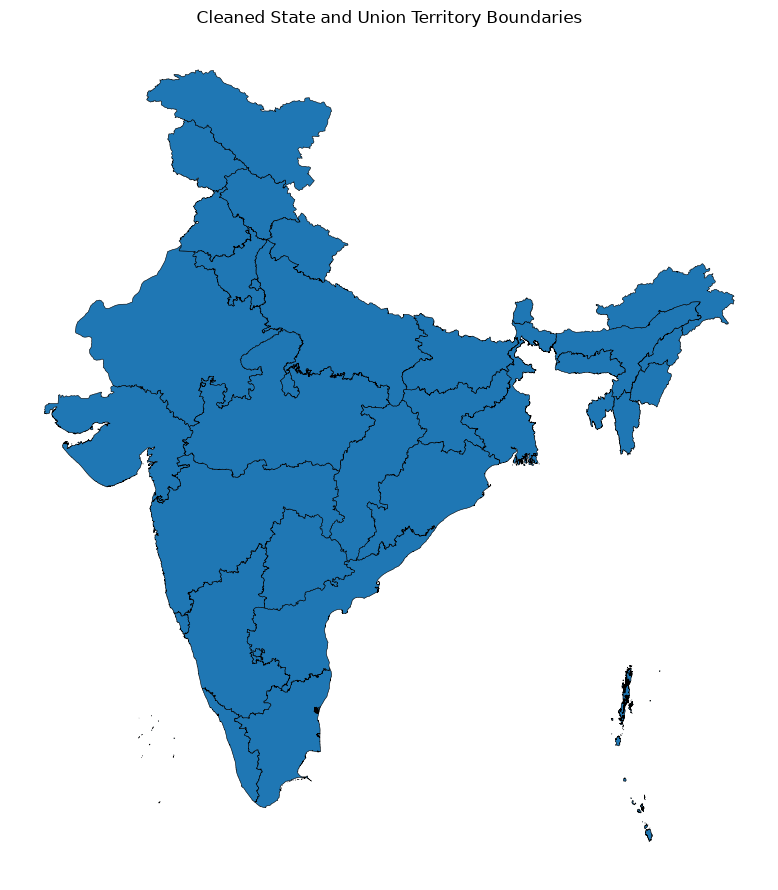

In [104]:

# VISUALIZE CLEANED BOUNDARIES

fig, ax = plt.subplots(figsize=(8, 9))

df.plot(
    ax=ax,
    edgecolor="black",
    linewidth=0.4
)

ax.set_title("Cleaned State and Union Territory Boundaries")
ax.set_axis_off()

plt.tight_layout()
plt.show()


In [105]:

# EXPORT CLEANED DATASET

os.makedirs("../Dataset/Cleaned datasets", exist_ok=True)

df.to_parquet(
    "../Dataset/Cleaned datasets/States_and_Union_Territories_Cleaned.parquet",
    index=False
)

print("Cleaned dataset exported successfully.")
print("Output path:")
print(
    "../Dataset/Cleaned datasets/"
    "States_and_Union_Territories_Cleaned.parquet"
)

print("Exported shape:", df.shape)


Cleaned dataset exported successfully.
Output path:
../Dataset/Cleaned datasets/States_and_Union_Territories_Cleaned.parquet
Exported shape: (36, 8)


# National Highway

In [106]:
hw = gpd.read_parquet(
    "../Dataset/Raw datasets/National_Highways.parquet"
)
highways = hw.copy()
print("Original dataset shape:", highways.shape)
print("Original CRS:", highways.crs)
print("Total columns:", len(highways.columns))

highways.head()


Original dataset shape: (10317, 65)
Original CRS: OGC:CRS84
Total columns: 65


,id,gid,objectid_1,objectid_2,objectid_3,objectid,i,j,state_ut,road_name,...,level_3,level_4,level_5,shape_leng,shape_le_1,shape_le_2,status,status_1,project_na,geometry
0,national_highway_uapdated_30_06_2022_departmen...,3113,16,2108,2097,2224,1699,1695,Karnataka,NH-66,...,Other National Highways,Coastal Roads,Others,0.35562340627,0.35562340627,0.35562340627,EXISTING,NaN,NaN,"LINESTRING (74.7359 13.34655, 74.73583 13.3463..."
1,national_highway_uapdated_30_06_2022_departmen...,3457,365,8280,8289,2224,1699,1695,Karnataka,NH-66,...,Other National Highways,Economic Corridors,Bharatmala Pariyojana Phase I,0.35562340627,0.35562340627,0.35562340627,EXISTING,NaN,NaN,"LINESTRING (74.7359 13.34655, 74.73583 13.3463..."
2,national_highway_uapdated_30_06_2022_departmen...,3460,368,8283,8292,2229,1695,1707,Karnataka,NH-66,...,Other National Highways,Economic Corridors,Bharatmala Pariyojana Phase I,0.60510779077,0.60510779077,0.60510779077,EXISTING,NaN,NaN,"LINESTRING (74.7359 13.34655, 74.73702 13.3495..."
3,national_highway_uapdated_30_06_2022_departmen...,3144,49,2207,2196,2229,1695,1707,Karnataka,NH-66,...,Other National Highways,Coastal Roads,Others,0.60510779077,0.60510779077,0.60510779077,EXISTING,NaN,NaN,"LINESTRING (74.7359 13.34655, 74.73702 13.3495..."
4,national_highway_uapdated_30_06_2022_departmen...,3175,80,2238,2227,2260,1697,1707,Karnataka,NH-766C,...,Other National Highways,NaN,NaN,0.40357750733,0.40357750733,0.40357750733,EXISTING,NaN,NaN,"LINESTRING (74.62976 13.85611, 74.63143 13.856..."


In [107]:
# Project settings
METRIC_CRS = "EPSG:7755"
SEGMENT_LENGTH_M = 25_000

TARGET_HIGHWAYS = [
    "NH-44",
    "NH-48",
    "NH-16",
    "NH-66",
    "NH-544",
    "NH-52"
]

In [108]:
# Inspect data types and non-null counts
highways.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 10317 entries, 0 to 10316
Data columns (total 65 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   id          10317 non-null  str     
 1   gid         10317 non-null  str     
 2   objectid_1  10317 non-null  str     
 3   objectid_2  10317 non-null  str     
 4   objectid_3  10317 non-null  str     
 5   objectid    10317 non-null  str     
 6   i           9398 non-null   str     
 7   j           9673 non-null   str     
 8   state_ut    10316 non-null  str     
 9   road_name   9835 non-null   str     
 10  greenfield  9456 non-null   str     
 11  road_type   10317 non-null  str     
 12  lane_statu  9516 non-null   str     
 13  completion  9453 non-null   str     
 14  completi_1  9453 non-null   str     
 15  speed_to_i  9394 non-null   str     
 16  ij          9398 non-null   str     
 17  length_2    10317 non-null  str     
 18  toll_type   9395 non-null   str     
 

In [109]:
# Check missing values
print("\nMissing values by column:")
print(
    highways.isna()
    .sum()
    .sort_values(ascending=False)
)


Missing values by column:
project_na    9942
status_1      9938
add_road      8640
level_5       6253
ro_missing    5959
              ... 
gis_length       0
shape_le_2       0
shape_le_1       0
shape_leng       0
geometry         0
Length: 65, dtype: int64


In [110]:
# Retain only attributes required for highway analysis
keep_columns = [
    "state_ut",
    "road_name",
    "road_type",
    "status",
    "geometry"
]

highways_clean = highways[keep_columns].copy()

print("Shape after column selection:", highways_clean.shape)

Shape after column selection: (10317, 5)


In [111]:
# Standardize whitespace and string data types
text_columns = [
    "state_ut",
    "road_name",
    "road_type",
    "status"
]

for col in text_columns:
    highways_clean[col] = (
        highways_clean[col]
        .astype("string")
        .str.strip()
    )


In [112]:
# Replace known invalid road-name placeholders
highways_clean["road_name"] = (
    highways_clean["road_name"]
    .replace({
        "": pd.NA,
        "Delete": pd.NA
    })
)


In [113]:
# Standardize known state-name variants
highways_clean["state_ut"] = (
    highways_clean["state_ut"]
    .replace({
        "MADHYA PRADESH": "Madhya Pradesh",
        "MADHYAPRADESH": "Madhya Pradesh",
        "Daman Diu": "Daman and Diu"
    })
)

print("Text cleaning completed.")

Text cleaning completed.


In [114]:
# Verify that a CRS is available
if highways_clean.crs is None:
    raise ValueError(
        "The source CRS is missing. Verify the original dataset."
    )


In [115]:
# Remove missing geometries
missing_geometry = highways_clean.geometry.isna().sum()

highways_clean = highways_clean.loc[
    highways_clean.geometry.notna()
].copy()

In [116]:
# Remove empty geometries
empty_geometry = highways_clean.geometry.is_empty.sum()

highways_clean = highways_clean.loc[
    ~highways_clean.geometry.is_empty
].copy()

In [117]:
# Repair invalid geometries
invalid_before = (~highways_clean.geometry.is_valid).sum()

if invalid_before > 0:
    invalid_mask = ~highways_clean.geometry.is_valid

    highways_clean.loc[invalid_mask, "geometry"] = (
        highways_clean.loc[invalid_mask, "geometry"].make_valid()
    )


In [118]:
# Keep line-based features for highway analysis
line_types = ["LineString", "MultiLineString"]

non_line_mask = ~highways_clean.geometry.geom_type.isin(line_types)
non_line_count = int(non_line_mask.sum())

highways_clean = highways_clean.loc[
    ~non_line_mask
].copy()


In [119]:
# Final geometry validation
invalid_after = (~highways_clean.geometry.is_valid).sum()
empty_after = highways_clean.geometry.is_empty.sum()

print("Missing geometries removed:", missing_geometry)
print("Empty geometries found before cleaning:", empty_geometry)
print("Invalid geometries before repair:", invalid_before)
print("Non-line geometries excluded:", non_line_count)
print("Invalid geometries remaining:", invalid_after)
print("Empty geometries remaining:", empty_after)

if invalid_after > 0 or empty_after > 0:
    raise ValueError(
        "Geometry validation failed. Review the remaining geometries."
    )

Missing geometries removed: 0
Empty geometries found before cleaning: 0
Invalid geometries before repair: 0
Non-line geometries excluded: 0
Invalid geometries remaining: 0
Empty geometries remaining: 0


In [120]:
# Remove exact duplicate records
rows_before = len(highways_clean)

highways_clean = (
    highways_clean
    .drop_duplicates()
    .reset_index(drop=True)
)

rows_after = len(highways_clean)

print("Rows before deduplication:", rows_before)
print("Duplicate rows removed:", rows_before - rows_after)
print("Rows after deduplication:", rows_after)

Rows before deduplication: 10317
Duplicate rows removed: 806
Rows after deduplication: 9511


In [121]:
# Project to the selected metric CRS
highways_metric = highways_clean.to_crs(METRIC_CRS)

# Calculate length in kilometres
highways_clean["length_km"] = (
    highways_metric.geometry.length / 1000
)

# Check calculated lengths
print("Missing lengths:", highways_clean["length_km"].isna().sum())

print(
    "Zero or negative lengths:",
    (highways_clean["length_km"] <= 0).sum()
)

print("\nLength summary in kilometres:")
print(highways_clean["length_km"].describe())

Missing lengths: 0
Zero or negative lengths: 0

Length summary in kilometres:
count    9.511000e+03
mean     1.721172e+01
std      2.617457e+01
min      2.803631e-09
25%      2.295063e+00
50%      8.134451e+00
75%      2.333896e+01
max      1.088454e+03
Name: length_km, dtype: float64


In [122]:
print("CLEANED MASTER DATASET")
print("=" * 45)

print("Dataset shape:", highways_clean.shape)
print("CRS:", highways_clean.crs)

print("\nMissing values:")
print(highways_clean.isna().sum())

print("\nDuplicate rows:", highways_clean.duplicated().sum())

print(
    "Duplicate geometries:",
    highways_clean.geometry.duplicated().sum()
)

print(
    "Invalid geometries:",
    (~highways_clean.geometry.is_valid).sum()
)

print(
    "Empty geometries:",
    highways_clean.geometry.is_empty.sum()
)

print("\nGeometry types:")
print(highways_clean.geometry.geom_type.value_counts())

print(
    "\nMissing lengths:",
    highways_clean["length_km"].isna().sum()
)

print(
    "Zero or negative lengths:",
    (highways_clean["length_km"] <= 0).sum()
)

CLEANED MASTER DATASET
Dataset shape: (9511, 6)
CRS: OGC:CRS84

Missing values:
state_ut       1
road_name    496
road_type      0
status        55
geometry       0
length_km      0
dtype: int64

Duplicate rows: 0
Duplicate geometries: 4
Invalid geometries: 0
Empty geometries: 0

Geometry types:
LineString         9257
MultiLineString     254
Name: count, dtype: int64

Missing lengths: 0
Zero or negative lengths: 0


In [123]:
# Select existing National Highways from the target list
highways_nh = highways_clean.loc[
    highways_clean["road_type"].eq("National Highway")
    & highways_clean["status"].eq("EXISTING")
    & highways_clean["road_name"].isin(TARGET_HIGHWAYS)
].copy()

print("TARGET HIGHWAYS")
print("=" * 45)

print("Target dataset shape:", highways_nh.shape)

print("\nRecords per highway:")
print(
    highways_nh["road_name"]
    .value_counts()
    .sort_index()
)

TARGET HIGHWAYS
Target dataset shape: (744, 6)

Records per highway:
road_name
NH-16      91
NH-44     239
NH-48     151
NH-52     115
NH-544     15
NH-66     133
Name: count, dtype: int64[pyarrow]


In [124]:
# Convert selected highways to the metric CRS
roads = highways_nh.to_crs(METRIC_CRS).copy()

# Extract line components from supported geometry types
def extract_lines(geom):
    if geom is None or geom.is_empty:
        return []

    if geom.geom_type == "LineString":
        return [geom]

    if geom.geom_type in [
        "MultiLineString",
        "GeometryCollection"
    ]:
        lines = []

        for part in geom.geoms:
            lines.extend(extract_lines(part))

        return lines

    return []


# Merge geometries separately for each highway name
corridors = {}

for highway, group in roads.groupby("road_name"):

    dissolved = unary_union(group.geometry.tolist())

    if dissolved.geom_type == "MultiLineString":
        merged = linemerge(dissolved)
    else:
        merged = dissolved

    corridors[highway] = extract_lines(merged)

print("Highway corridors prepared:", len(corridors))

for highway, components in corridors.items():
    print(
        highway,
        "- connected components:",
        len(components)
    )

Highway corridors prepared: 6
NH-16 - connected components: 95
NH-44 - connected components: 70
NH-48 - connected components: 77
NH-52 - connected components: 31
NH-544 - connected components: 2
NH-66 - connected components: 192


In [125]:
# Generate segments with a maximum intended length of 25 km
records = []

for highway, components in corridors.items():

    for component_id, line in enumerate(components, start=1):

        if line.length <= 0:
            continue

        segment_count = int(
            np.ceil(line.length / SEGMENT_LENGTH_M)
        )

        for i in range(segment_count):

            start_m = i * SEGMENT_LENGTH_M

            end_m = min(
                (i + 1) * SEGMENT_LENGTH_M,
                line.length
            )

            segment = substring(
                line,
                start_m,
                end_m
            )

            if segment.is_empty or segment.length <= 0:
                continue

            midpoint = segment.interpolate(
                0.5,
                normalized=True
            )

            records.append({
                "road_name": highway,
                "component_id": component_id,
                "segment_number": i + 1,
                "segment_length_km": segment.length / 1000,
                "midpoint_x": midpoint.x,
                "midpoint_y": midpoint.y,
                "geometry": segment
            })

segments = gpd.GeoDataFrame(
    records,
    geometry="geometry",
    crs=METRIC_CRS
)

print("Total segments:", len(segments))

print("\nSegments by highway:")
print(segments.groupby("road_name").size())

print("\nSegment length summary:")
print(segments["segment_length_km"].describe())

Total segments: 876

Segments by highway:
road_name
NH-16     150
NH-44     197
NH-48     166
NH-52     110
NH-544     14
NH-66     239
dtype: int64

Segment length summary:
count    8.760000e+02
mean     1.369687e+01
std      1.152794e+01
min      8.859810e-12
25%      1.365455e-01
50%      1.788260e+01
75%      2.500000e+01
max      2.500000e+01
Name: segment_length_km, dtype: float64


In [126]:
# ADD — Calculate geographic midpoint coordinates

midpoints = gpd.GeoSeries(
    segments.geometry.interpolate(0.5, normalized=True),
    index=segments.index,
    crs=METRIC_CRS
).to_crs("EPSG:4326")

segments["midpoint_lon"] = midpoints.x
segments["midpoint_lat"] = midpoints.y

print("Geographic midpoints added successfully.")

Geographic midpoints added successfully.


In [127]:

# MODIFIED — Validate both projected and geographic midpoints

print(
    "Missing projected midpoint coordinates:",
    segments[["midpoint_x", "midpoint_y"]]
    .isna().any(axis=1).sum()
)

print(
    "Missing geographic midpoint coordinates:",
    segments[["midpoint_lon", "midpoint_lat"]]
    .isna().any(axis=1).sum()
)

print(
    "Invalid longitude values:",
    (~segments["midpoint_lon"].between(-180, 180)).sum()
)

print(
    "Invalid latitude values:",
    (~segments["midpoint_lat"].between(-90, 90)).sum()
)


Missing projected midpoint coordinates: 0
Missing geographic midpoint coordinates: 0
Invalid longitude values: 0
Invalid latitude values: 0


In [128]:
# Identify segments requiring review
short_segments = segments.loc[
    segments["segment_length_km"] < 1
].copy()

tiny_segments = segments.loc[
    segments["segment_length_km"] < 0.001
].copy()

print("Segments shorter than 1 km:", len(short_segments))
print("Segments shorter than 1 metre:", len(tiny_segments))

print("\nShort segments by highway:")
print(short_segments.groupby("road_name").size())

print("\nShortest segments:")
display(
    short_segments[
        [
            "road_name",
            "component_id",
            "segment_number",
            "segment_length_km"
        ]
    ]
    .sort_values("segment_length_km")
    .head(20)
)

Segments shorter than 1 km: 288
Segments shorter than 1 metre: 32

Short segments by highway:
road_name
NH-16     61
NH-44     25
NH-48     51
NH-52      6
NH-66    145
dtype: int64

Shortest segments:


,road_name,component_id,segment_number,segment_length_km
728,NH-66,59,1,8.859810e-12
193,NH-44,21,1,4.183702e-11
730,NH-66,61,1,5.975180e-11
403,NH-48,16,1,1.760645e-09
688,NH-66,19,1,5.635337e-09
785,NH-66,109,1,8.806792e-09
784,NH-66,108,1,8.806803e-09
731,NH-66,62,1,2.598097e-08
769,NH-66,95,1,6.350581e-08
140,NH-16,87,1,4.940164e-07


In [129]:
print("Geographic midpoints added successfully.")
display(
    segments[
        ["road_name", "segment_length_km",
         "midpoint_lon", "midpoint_lat"]
    ].head()
)


Geographic midpoints added successfully.


,road_name,segment_length_km,midpoint_lon,midpoint_lat
0,NH-16,0.007991,79.907761,14.280737
1,NH-16,0.160799,79.907978,14.281437
2,NH-16,25.000000,80.048974,13.570458
3,NH-16,25.000000,79.967126,13.771512
4,NH-16,25.000000,79.900069,13.977353


In [130]:
print("SEGMENT VALIDATION")
print("=" * 45)

print("Shape:", segments.shape)
print("CRS:", segments.crs)

print(
    "Missing geometries:",
    segments.geometry.isna().sum()
)

print(
    "Empty geometries:",
    segments.geometry.is_empty.sum()
)

print(
    "Invalid geometries:",
    (~segments.geometry.is_valid).sum()
)

print(
    "Missing segment lengths:",
    segments["segment_length_km"].isna().sum()
)

print(
    "Zero or negative segment lengths:",
    (segments["segment_length_km"] <= 0).sum()
)

print(
    "Segments longer than 25 km:",
    (segments["segment_length_km"] > 25.001).sum()
)

print(
    "Missing midpoint coordinates:",
    segments[["midpoint_x", "midpoint_y"]]
    .isna().any(axis=1).sum()
)

SEGMENT VALIDATION
Shape: (876, 9)
CRS: EPSG:7755
Missing geometries: 0
Empty geometries: 0
Invalid geometries: 0
Missing segment lengths: 0
Zero or negative segment lengths: 0
Segments longer than 25 km: 0
Missing midpoint coordinates: 0


In [131]:
print("CLEANED HIGHWAY DATASET")
print("Shape:", highways_clean.shape)
print("CRS:", highways_clean.crs)

print("\nColumn names:")
print(highways_clean.columns.tolist())

print("\nCleaned dataset reopened successfully.")


CLEANED HIGHWAY DATASET
Shape: (9511, 6)
CRS: OGC:CRS84

Column names:
['state_ut', 'road_name', 'road_type', 'status', 'geometry', 'length_km']

Cleaned dataset reopened successfully.


In [132]:

# Reopen exported spatial files to verify

# Save cleaned dataset

highways_clean.to_crs("EPSG:4326").to_file(
    "../Dataset/Cleaned datasets/highways_clean.geojson",
    driver="GeoJSON"
)

print("Cleaned dataset saved successfully.")
print("Shape:", highways_clean.shape)


Cleaned dataset saved successfully.
Shape: (9511, 6)


# EV Gap Analysis

# PROJECT SETTINGS & IMPORTS

In [133]:
# Limit OpenMP threads to reduce the common KMeans / MKL warning on Windows.
os.environ["OMP_NUM_THREADS"] = "1"

# Hide non-critical warnings so that notebook outputs remain easier to read.
warnings.filterwarnings("ignore")


In [134]:
# Apply a consistent Seaborn plotting style.
sns.set_style("whitegrid")

# Set default figure resolution and title style.
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titleweight": "bold"
})


In [135]:
# Folder containing the cleaned input datasets.
DATA = Path("../data/Cleaned datasets")

# Main output folder.
OUT = Path("../Visualization")

# Create folders for charts and tables if they
# do not already exist.
(OUT / "figures").mkdir(parents=True, exist_ok=True)
(OUT / "tables").mkdir(parents=True, exist_ok=True)


In [136]:
# Projected CRS used for distance and length calculations.
# EPSG:7755 uses metres as the distance unit.
METRIC_CRS = "EPSG:7755"

# A charger within 5 km of a mapped highway is considered to be associated with that highway.
CORRIDOR_KM = 5

# Target highway segment length.
SEG_KM = 25

# A highway segment is considered a charging gap when the nearest fast charger is more than 50 km away.
GAP_KM = 50

# Ignore very short highway fragments when building continuous highway components.
MIN_COMPONENT_KM = 5

# Minimum number of car + bus EV registrations used when ranking EV-desert states.
MIN_DEMAND = 5000

# Definition of a fast charger for the main analysis. Chargers with >= 25 kW are treated as fast.
FAST_KW = 25

# False = use the power-based definition above.
# True = use the OpenChargeMap fast-charging flag instead.
USE_DATASET_FLAG = False

# Six target highways selected for detailed corridor analysis.
TARGET_HIGHWAYS = [
    "NH-44",
    "NH-48",
    "NH-16",
    "NH-66",
    "NH-544",
    "NH-52"
]

# Years available in the EV registration datasets.
YEARS = [str(y) for y in range(2017, 2027)]

# Standardized state name used for Dadra and Nagar Haveli and Daman and Diu.
DNHDD = "dadra and nagar haveli and daman and diu"


In [137]:
def finish(name: str):
    """
    Save the current Matplotlib figure as a PNG
    and display it in the notebook.
    """

    # Adjust spacing so labels do not overlap.
    plt.tight_layout()

    # Save the figure inside the outputs/figures folder.
    plt.savefig(
        OUT / "figures" / f"{name}.png",
        bbox_inches="tight"
    )

    # Display the figure in the notebook.
    plt.show()

# LOAD CLEANED DATASETS

In [138]:
# Load all cleaned datasets required for the analysis.
states_gdf   = gpd.read_parquet("../Dataset/Cleaned datasets/States_and_Union_Territories_Cleaned.parquet")
highways_gdf = gpd.read_file("../Dataset/Cleaned datasets/highways_clean.geojson")
ev_registration = pd.read_csv("../Dataset/Cleaned datasets/Ev_registration_cleaned.csv")
chargers_df  = pd.read_csv("../Dataset/Cleaned datasets/Ev_chargers_cleaned.csv")

In [139]:
# Convert EV year column names to strings so that they match the YEARS list defined above.
ev_registration.columns = ev_registration.columns.astype(str)

In [140]:
# Print dataset shapes
for name, obj in [
    ("states", states_gdf),
    ("highways", highways_gdf),
    ("ev_registration", ev_registration),
    ("chargers", chargers_df),
]:
    print(f"{name:10s}", obj.shape)

states     (36, 8)
highways   (9511, 6)
ev_registration (36, 12)
chargers   (1841, 15)


# DATA QUALITY CHECKS

In [141]:
# Add all yearly registrations and compare the result with the provided "Total" column.
# A mismatch of zero means the yearly values correctly reproduce the Total column.
mismatch = (ev_registration[YEARS].sum(axis=1) - ev_registration["Total"]).abs().sum()
print("ev_registration: total mismatch =", mismatch)


ev_registration: total mismatch = 0


In [142]:
# Create charger-power groups so that we can compare the dataset's fast-charging flag against actual power.
band = pd.cut(chargers_df["max_power_kw"], [-0.1, 0, 7.5, 22, 50, 1000],
              labels=["0 (missing)", "0-7.5", "7.5-22", "22-50", ">50"])
display(pd.crosstab(band, chargers_df["has_fast_charging"],
                    rownames=["max power (kW)"], colnames=["dataset flag"]))
flag = chargers_df["has_fast_charging"].astype(bool)
print(f"Flag=True but power < {FAST_KW} kW :", int((flag & (chargers_df['max_power_kw'] < FAST_KW)).sum()))
print(f"Flag=False but power >= {FAST_KW} kW:", int((~flag & (chargers_df['max_power_kw'] >= FAST_KW)).sum()))

dataset flag,False,True
max power (kW),,
0 (missing),101,0
0-7.5,212,1
7.5-22,42,5
22-50,85,763
>50,16,616


Flag=True but power < 25 kW : 53
Flag=False but power >= 25 kW: 99


In [143]:
# Check whether any charger IDs are duplicated.
print("Duplicate IDs:", chargers_df["ID"].duplicated().sum())
# Count chargers where power was recorded as zero.
print("Zero-kW chargers:", (chargers_df["max_power_kw"] == 0).sum())

Duplicate IDs: 0
Zero-kW chargers: 101


# STATE NAME NORMALIZATION

In [144]:
# Common alternative names found in different datasets.
ALIASES = {
    "orissa": "odisha",
    "uttaranchal": "uttarakhand",
    "pondicherry": "puducherry",
    "nct of delhi": "delhi",
    "delhi nct": "delhi",
    "ut of dnh and dd": DNHDD,
    "dnh and dd": DNHDD,
    "dadra and nagar haveli": DNHDD,
    "daman and diu": DNHDD,
}

In [145]:
def make_key(s: pd.Series) -> pd.Series:
    s = (
        s.astype(str)
        .str.lower()
        .str.replace("&", "and", regex=False)
        .str.replace(r"[^a-z\s]", " ", regex=True)
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
        .str.replace("islands", "island", regex=False)
    )
    return s.replace(ALIASES)

In [146]:
# Create standardized keys for state boundaries.
states_gdf["state_key"] = make_key(states_gdf["state"])
ev_registration["state_key"] = make_key(ev_registration["State"])

key2name = states_gdf.drop_duplicates("state_key").set_index("state_key")["state"].to_dict()


In [147]:
# Compare the state keys in the EV registration dataset against the state boundary dataset.
a = sorted(set(states_gdf.state_key) - set(ev_registration.state_key))
b = sorted(set(ev_registration.state_key) - set(states_gdf.state_key))
print("ev_registration", "| in map not in EV:", a, "| in EV not in map:", b)


ev_registration | in map not in EV: [] | in EV not in map: []


# Prepare charger geodata and define fast chargers

In [148]:
# Keep only chargers currently marked as operational.
chargers_op = chargers_df[chargers_df["is_operational"] == True].copy()
chargers_op["max_power_kw"] = chargers_op["max_power_kw"].replace(0, np.nan)

In [149]:
# Define fast chargers
if USE_DATASET_FLAG:
    chargers_op["is_fast"] = chargers_op["has_fast_charging"].astype(bool)
else:
    chargers_op["is_fast"] = chargers_op["max_power_kw"] >= FAST_KW

In [150]:
# Convert to GeoDataFrame
chargers_gdf = gpd.GeoDataFrame(
    chargers_op,
    geometry=gpd.points_from_xy(chargers_op["longitude"], chargers_op["latitude"]),
    crs="EPSG:4326"
).to_crs(METRIC_CRS)

In [151]:
# States in metric CRS
states_m = states_gdf.to_crs(METRIC_CRS)
st_small = states_m[["state_key", "geometry"]].rename(columns={"state_key": "state_geo"})

In [152]:
# Spatial join: assign chargers to states
chargers_join = gpd.sjoin(chargers_gdf, st_small, how="left", predicate="within")
chargers_join = chargers_join[~chargers_join.index.duplicated()].drop(columns="index_right")

In [153]:
# Handle missing state assignments (snap to nearest within 25 km)
miss = chargers_join["state_geo"].isna()
if miss.any():
    fix = gpd.sjoin_nearest(
        chargers_join.loc[miss].drop(columns="state_geo"),
        st_small,
        how="left",
        max_distance=25_000
    )
    fix = fix[~fix.index.duplicated()]
    chargers_join.loc[miss, "state_geo"] = fix["state_geo"]

chargers_gdf = chargers_join.dropna(subset=["state_geo"]).copy()
chargers_gdf["state_name"] = chargers_gdf["state_geo"].map(key2name)

In [154]:
# Summary
print("Operational chargers:", len(chargers_gdf))
print(f"Fast by power rule (>= {FAST_KW} kW):", (chargers_gdf["max_power_kw"] >= FAST_KW).sum())
print("Fast by dataset flag:", chargers_gdf["has_fast_charging"].astype(bool).sum())
print("Fast chargers used in analysis:", chargers_gdf["is_fast"].sum())

Operational chargers: 1823
Fast by power rule (>= 25 kW): 1421
Fast by dataset flag: 1375
Fast chargers used in analysis: 1421


In [155]:
NAVY_BLUE = "#102A4C"
EMERALD_GREEN = "#00D878"
SKY_BLUE = "#5AA9E6"
LIGHT_BLUE = "#DCEAF5"
WHITE = "#FFFFFF"
RED = "#E5484D"

# Q How fast is EV adoption growing?

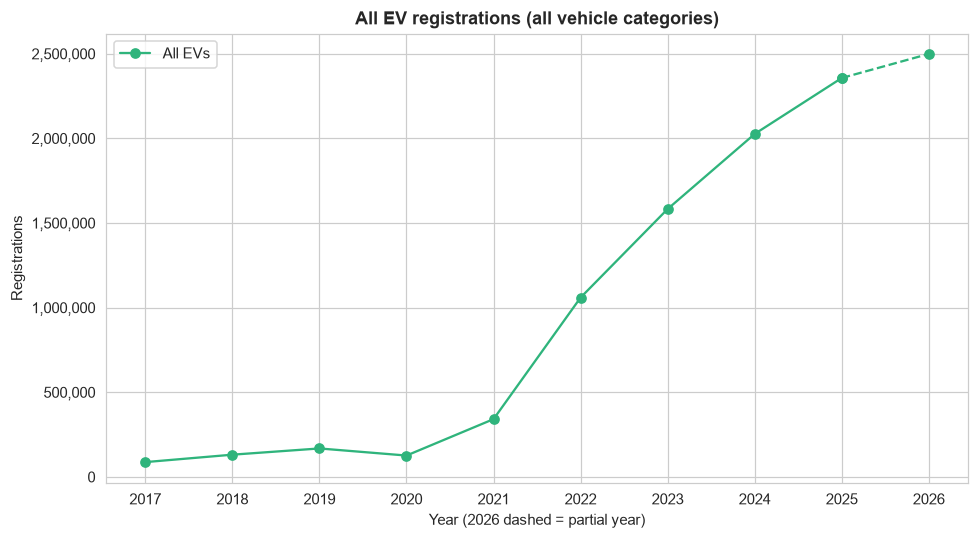

In [156]:
# EV registration growth: all vehicle categories combined
fig, ax = plt.subplots(figsize=(9, 5))

def plot_line(ax, series, label):
    color = plt.cm.viridis(0.65)
    ax.plot(YEARS[:-1], series.values[:-1], marker="o",
            color=color, label=label)
    ax.plot(YEARS[-2:], series.values[-2:], ls="--",
            marker="o", color=color)

plot_line(ax, ev_registration[YEARS].sum(), "All EVs")

ax.set_title("All EV registrations (all vehicle categories)")
ax.set_xlabel("Year (2026 dashed = partial year)")
ax.set_ylabel("Registrations")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.legend()

plt.tight_layout()
finish("01_ev_growth")

# Q Which states drive EV adoption growth?

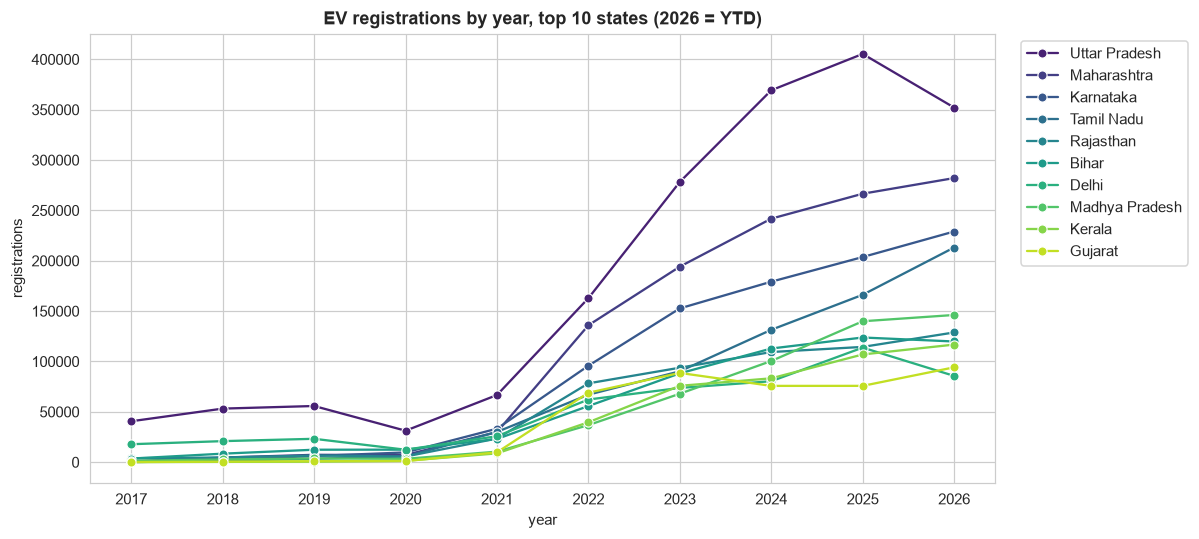

In [157]:
# Top 10 states: EV registration trends using Viridis
top10_states = ev_registration.nlargest(10, "Total")

trend_data = top10_states.melt(
    id_vars="State",
    value_vars=YEARS,
    var_name="year",
    value_name="registrations"
)

plt.figure(figsize=(11, 5))

sns.lineplot(
    data=trend_data,
    x="year",
    y="registrations",
    hue="State",
    hue_order=top10_states["State"].tolist(),
    palette="viridis",
    marker="o"
)

plt.title("EV registrations by year, top 10 states (2026 = YTD)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()

finish("02_top10_state_trend")

# Q HOW POWERFUL ARE THE CHARGERS?

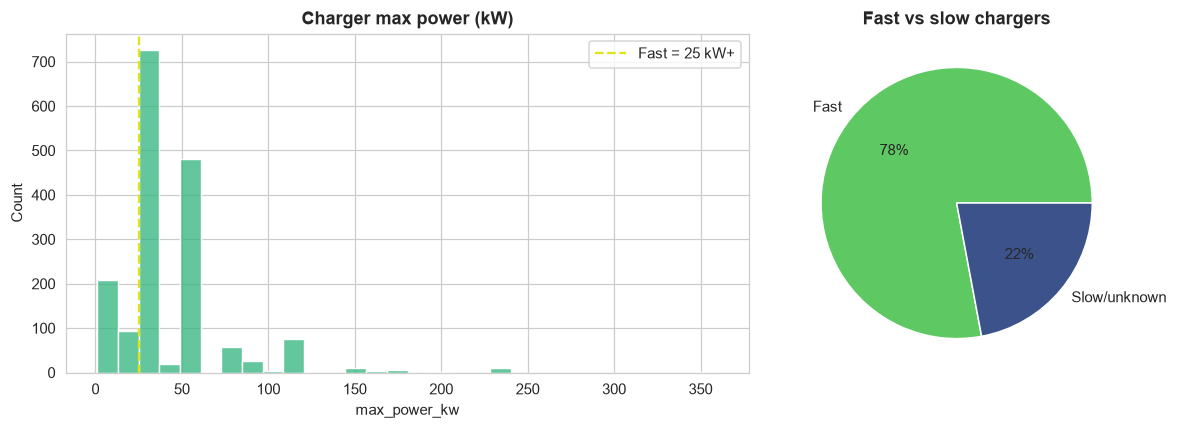

In [158]:
# Charger power distribution using Viridis
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Histogram of charger power
sns.histplot(
    chargers_gdf["max_power_kw"].dropna(),
    bins=30,
    color=plt.cm.viridis(0.65),
    ax=ax[0]
)
ax[0].axvline(
    FAST_KW, color=plt.cm.viridis(0.95),
    ls="--", label=f"Fast = {FAST_KW} kW+"
)
ax[0].legend()
ax[0].set_title("Charger max power (kW)")

# Fast vs slow pie chart
charger_counts = chargers_gdf["is_fast"].map(
    {True: "Fast", False: "Slow/unknown"}
).value_counts()

charger_counts.plot.pie(
    autopct="%1.0f%%",
    colors=[plt.cm.viridis(0.75), plt.cm.viridis(0.25)],
    ax=ax[1]
)
ax[1].set_ylabel("")
ax[1].set_title("Fast vs slow chargers")

plt.tight_layout()
finish("03_charger_power")

# Q Which operators run the chargers?

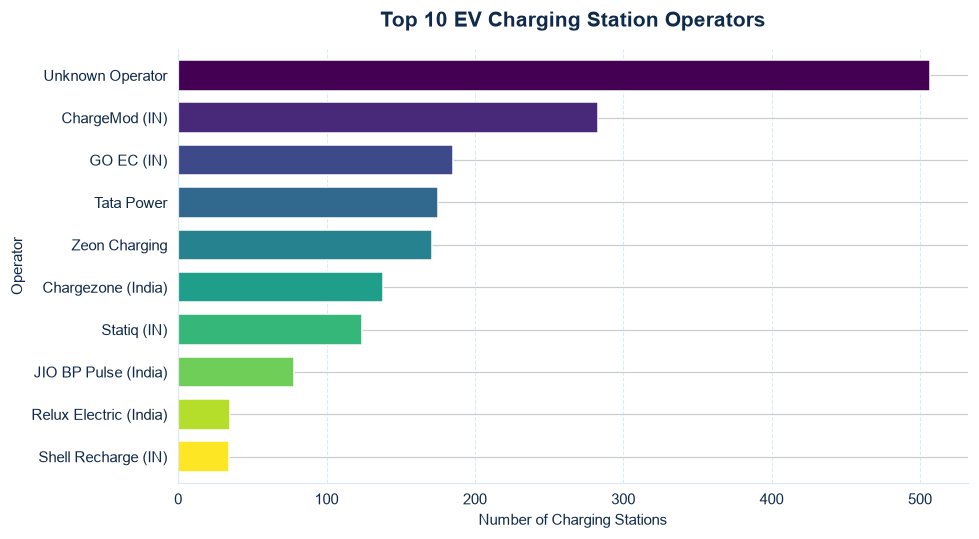

Share with 'Unknown Operator': 27.8 %


In [159]:
# Top 10 EV charging station operators — Viridis palette

import matplotlib.pyplot as plt

# Count charging stations by operator
operators = chargers_gdf["operator"].value_counts()
top_10_operators = operators.head(10)

# Generate 10 distinct colors from Viridis
operator_colors = plt.cm.viridis(
    [i / (len(top_10_operators) - 1)
     for i in range(len(top_10_operators))]
)

# Create chart
fig, ax = plt.subplots(figsize=(9, 5))

fig.patch.set_facecolor("#FFFFFF")
ax.set_facecolor("#FFFFFF")

top_10_operators.plot.barh(
    ax=ax,
    color=operator_colors,
    edgecolor="#FFFFFF",
    linewidth=1,
    width=0.72
)

# Highest-ranked operator at the top
ax.invert_yaxis()

# Titles and labels
ax.set_title(
    "Top 10 EV Charging Station Operators",
    fontsize=14,
    fontweight="bold",
    color="#102A4C",
    pad=15
)

ax.set_xlabel("Number of Charging Stations", color="#102A4C")
ax.set_ylabel("Operator", color="#102A4C")

# Grid and styling
ax.tick_params(axis="both", colors="#102A4C")

ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.7,
    color="#DCEAF5"
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#DCEAF5")
ax.spines["bottom"].set_color("#DCEAF5")

plt.tight_layout()

finish("04_top_operators")

# Unknown operator percentage
unknown_share = round(
    operators.get("Unknown Operator", 0) / len(chargers_gdf) * 100,
    1
)

print("Share with 'Unknown Operator':", unknown_share, "%")

# Q ARE CHARGERS IN EACH STATE FAST OR SLOW?

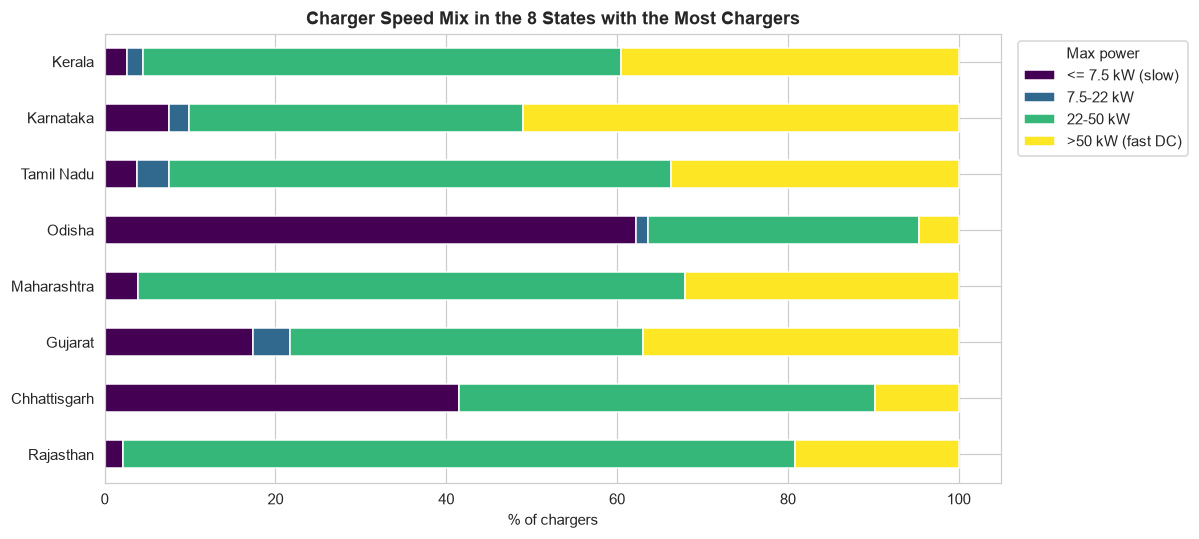

In [160]:
# Charger speed mix using Viridis
bins = [0, 7.5, 22, 50, 1000]
labels = ["<= 7.5 kW (slow)", "7.5-22 kW", "22-50 kW", ">50 kW (fast DC)"]

chargers_copy = chargers_gdf.copy()
chargers_copy["power_band"] = pd.cut(
    chargers_copy["max_power_kw"], bins=bins, labels=labels
)

# Top 8 states by charger count
top_states = chargers_copy["state_name"].value_counts().head(8).index

mix = (
    chargers_copy[chargers_copy["state_name"].isin(top_states)]
    .groupby(["state_name", "power_band"], observed=False)
    .size()
    .unstack(fill_value=0)
)

mix = mix.div(mix.sum(axis=1), axis=0) * 100

mix.loc[top_states[::-1]].plot(
    kind="barh",
    stacked=True,
    figsize=(11, 5),
    colormap="viridis"
)

plt.xlabel("% of chargers")
plt.ylabel("")
plt.title("Charger Speed Mix in the 8 States with the Most Chargers")
plt.legend(title="Max power", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()

finish("05_charger_speed_mix")

# Build the state-level demand-versus-supply table

In [161]:
# EV demand metrics from the combined EV registration dataset.
ev = ev_registration[["state_key", "2021", "2025", "Total"]].rename(columns={"Total": "ev_total"})
ev["ev_cagr_21_25"] = np.where(ev["2021"] > 0, (ev["2025"] / ev["2021"]) ** (1 / 4) - 1, np.nan)
ev = ev[["state_key", "ev_total", "ev_cagr_21_25"]]


In [162]:
# Charger supply metrics
chg = (
    chargers_gdf.groupby("state_geo")
    .agg(
        n_chargers=("ID", "count"),
        n_fast=("is_fast", "sum"),
        total_points=("total_points", "sum"),
        median_kw=("max_power_kw", "median"),
    )
    .reset_index()
    .rename(columns={"state_geo": "state_key"})
)

In [163]:
# Merge into master table
master = (
    states_gdf[["state", "state_key", "area_km2"]]
    .merge(ev, on="state_key", how="left")
    .merge(chg, on="state_key", how="left")
)

master[["n_chargers", "n_fast", "total_points"]] = master[["n_chargers", "n_fast", "total_points"]].fillna(0)


In [164]:
# Derived metrics
# The separate car and bus datasets are no longer used; use total EV registrations as demand.
master["ev_demand"] = master["ev_total"]
master["chargers_per_1000km2"] = master["n_chargers"] / master["area_km2"] * 1000
master["evs_per_charger"] = master["ev_total"] / master["n_chargers"].clip(lower=1)
master["evs_per_fast_charger"] = master["ev_demand"] / (master["n_fast"] + 1)  # avoid divide-by-zero
master["fast_per_100k_ev"] = (master["n_fast"] / master["ev_demand"] * 1e5).replace([np.inf, -np.inf], np.nan)


In [165]:
# EV desert definition based on total EV demand and fast-charger supply.
med_ev, med_fc = master["ev_demand"].median(), master["n_fast"].median()
master["ev_desert"] = (master["ev_demand"] >= med_ev) & (master["n_fast"] < med_fc)


In [166]:
# Display top states by total EVs per fast charger
display(
    master[["state", "ev_total", "ev_demand", "n_chargers", "n_fast", "evs_per_fast_charger", "ev_desert"]]
    .sort_values("evs_per_fast_charger", ascending=False)
    .reset_index(drop=True).head(15)
)


,state,ev_total,ev_demand,n_chargers,n_fast,evs_per_fast_charger,ev_desert
0,Bihar,560438,560438,1.0,0.0,560438.000000,True
1,Assam,384300,384300,2.0,0.0,384300.000000,True
2,Uttar Pradesh,1815492,1815492,29.0,20.0,86452.000000,False
3,Punjab,181928,181928,2.0,2.0,60642.666667,True
4,Tripura,45221,45221,0.0,0.0,45221.000000,False
5,Madhya Pradesh,513003,513003,13.0,11.0,42750.250000,False
6,West Bengal,341644,341644,9.0,7.0,42705.500000,False
7,Telangana,357920,357920,17.0,10.0,32538.181818,False
8,Delhi,515897,515897,34.0,17.0,28660.944444,False
9,Jharkhand,139850,139850,6.0,4.0,27970.000000,False


# Research question 2 — Where is demand high but fast-charger supply low?

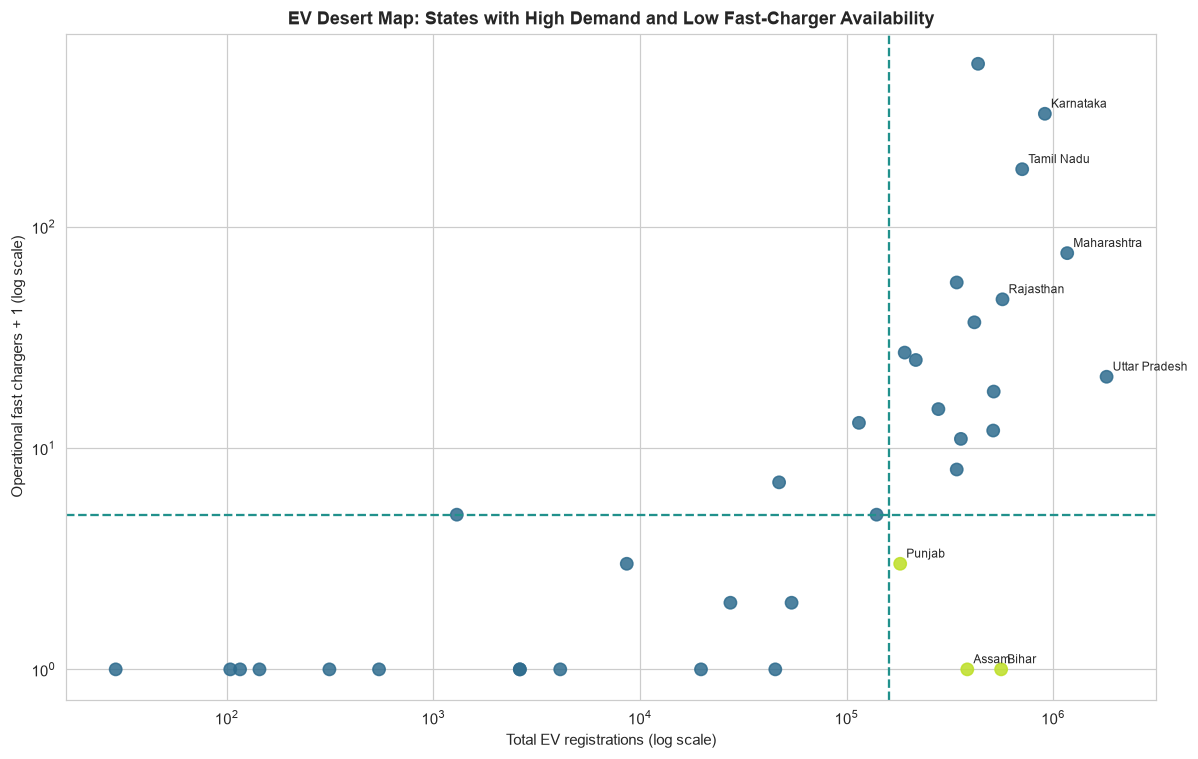

In [167]:
# EV Desert Quadrant using Viridis
d = master.copy()

fig, ax = plt.subplots(figsize=(11, 7))

ax.scatter(
    d["ev_demand"].clip(lower=1),
    d["n_fast"] + 1,
    c=np.where(d["ev_desert"], 0.9, 0.35),
    cmap="viridis",
    vmin=0,
    vmax=1,
    s=65,
    alpha=0.85
)

ax.set_xscale("log")
ax.set_yscale("log")
ax.axvline(med_ev, ls="--", color=plt.cm.viridis(0.5))
ax.axhline(med_fc + 1, ls="--", color=plt.cm.viridis(0.5))

# Annotate EV deserts and high-demand states
for _, r in d[
    d["ev_desert"] |
    (d["ev_demand"] >= d["ev_demand"].quantile(0.85))
].iterrows():
    ax.annotate(
        r["state"],
        (max(r["ev_demand"], 1), r["n_fast"] + 1),
        fontsize=8,
        xytext=(4, 4),
        textcoords="offset points"
    )

ax.set_xlabel("Total EV registrations (log scale)")
ax.set_ylabel("Operational fast chargers + 1 (log scale)")
ax.set_title("EV Desert Map: States with High Demand and Low Fast-Charger Availability")

plt.tight_layout()
finish("06_ev_desert_quadrant")

#  Q2 – TOP 12 EV DESERTS

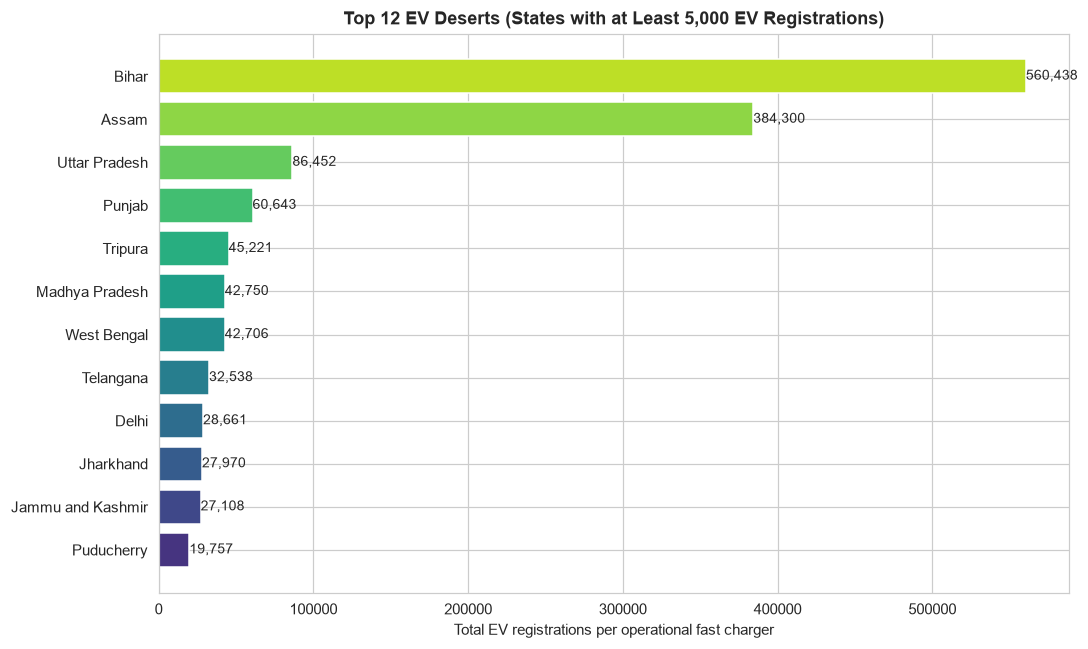

In [168]:
# Top 12 EV deserts using Viridis

top_ev_deserts = (
    master[master["ev_demand"] >= MIN_DEMAND]
    .nlargest(12, "evs_per_fast_charger")
    .iloc[::-1]
)

fig, ax = plt.subplots(figsize=(10, 6))

colors = plt.cm.viridis(
    np.linspace(0.15, 0.9, len(top_ev_deserts))
)

ax.barh(
    top_ev_deserts["state"],
    top_ev_deserts["evs_per_fast_charger"],
    color=colors
)

for y, v in enumerate(top_ev_deserts["evs_per_fast_charger"]):
    ax.text(v, y, f"{v:,.0f}", va="center", fontsize=9)

ax.set_xlabel("Total EV registrations per operational fast charger")
ax.set_title(
    f"Top 12 EV Deserts (States with at Least {MIN_DEMAND:,} EV Registrations)"
)

plt.tight_layout()
finish("07_top_ev_deserts")

# Prepare the national road network

In [169]:
hw_all = highways_gdf.copy()
if hw_all.crs is None:
    hw_all = hw_all.set_crs("EPSG:4326")

hw_all = hw_all.to_crs(METRIC_CRS)
hw_all = hw_all[hw_all.geometry.notna() & ~hw_all.geometry.is_empty][["road_name", "road_type", "geometry"]]
hw_all = hw_all.explode(index_parts=False).reset_index(drop=True)
hw_all = hw_all[hw_all.geom_type == "LineString"].reset_index(drop=True)

km_before = hw_all.length.sum() / 1000
hw_all = hw_all.loc[~hw_all.geometry.to_wkb().duplicated()].reset_index(drop=True)
print(f"Highway lines: {len(hw_all):,} | km before dedupe: {km_before:,.0f} | after: {hw_all.length.sum()/1000:,.0f}")

Highway lines: 11,231 | km before dedupe: 163,701 | after: 163,239


In [170]:
# Distance of chargers to highways
near = gpd.sjoin_nearest(chargers_gdf[["geometry"]], hw_all[["geometry"]], how="left", distance_col="d")
near = near[~near.index.duplicated()]
chargers_gdf["dist_to_hwy_km"] = near["d"] / 1000
chargers_gdf["on_corridor"] = chargers_gdf["dist_to_hwy_km"] <= CORRIDOR_KM

print(f"Share of chargers within {CORRIDOR_KM} km of a highway:", round(chargers_gdf["on_corridor"].mean(), 3))

Share of chargers within 5 km of a highway: 0.862


# Segment the national network and detect charging gaps

In [171]:
segments_list = []

for geom in hw_all.geometry:
    length = geom.length
    n_segments = max(1, int(round(length / (SEG_KM * 1000))))
    step = length / n_segments
    segments_list += [substring(geom, i * step, (i + 1) * step) for i in range(n_segments)]

seg_nat = gpd.GeoDataFrame(geometry=segments_list, crs=METRIC_CRS)
seg_nat["seg_km"] = seg_nat.length / 1000
seg_nat = seg_nat[seg_nat["seg_km"] > 0.5].reset_index(drop=True)

In [172]:
# Midpoints
midpoints = seg_nat.geometry.interpolate(0.5, normalized=True)
mid_gdf = gpd.GeoDataFrame(geometry=midpoints.values, crs=METRIC_CRS)

In [173]:
# Assign states
m1 = gpd.sjoin_nearest(mid_gdf, st_small, how="left")
m1 = m1[~m1.index.duplicated()]
seg_nat["state_key"] = m1["state_geo"]

In [174]:
# Distance to nearest fast charger
fast_chargers = chargers_gdf[chargers_gdf["is_fast"]]
tree = cKDTree(np.c_[fast_chargers.geometry.x, fast_chargers.geometry.y])
dist, _ = tree.query(np.c_[midpoints.x, midpoints.y])
seg_nat["dist_fast_km"] = dist / 1000
seg_nat["is_gap"] = seg_nat["dist_fast_km"] > GAP_KM
seg_nat["gap_km"] = seg_nat["seg_km"] * seg_nat["is_gap"]

print(f"Segments: {len(seg_nat):,} | gap segments: {seg_nat['is_gap'].sum():,} "
      f"({seg_nat.gap_km.sum():,.0f} km = {seg_nat.gap_km.sum()/seg_nat.seg_km.sum():.0%} of network)")

Segments: 11,046 | gap segments: 6,582 (98,551 km = 60% of network)


# Research question 4 — Where is fast charging missing on India's road network?

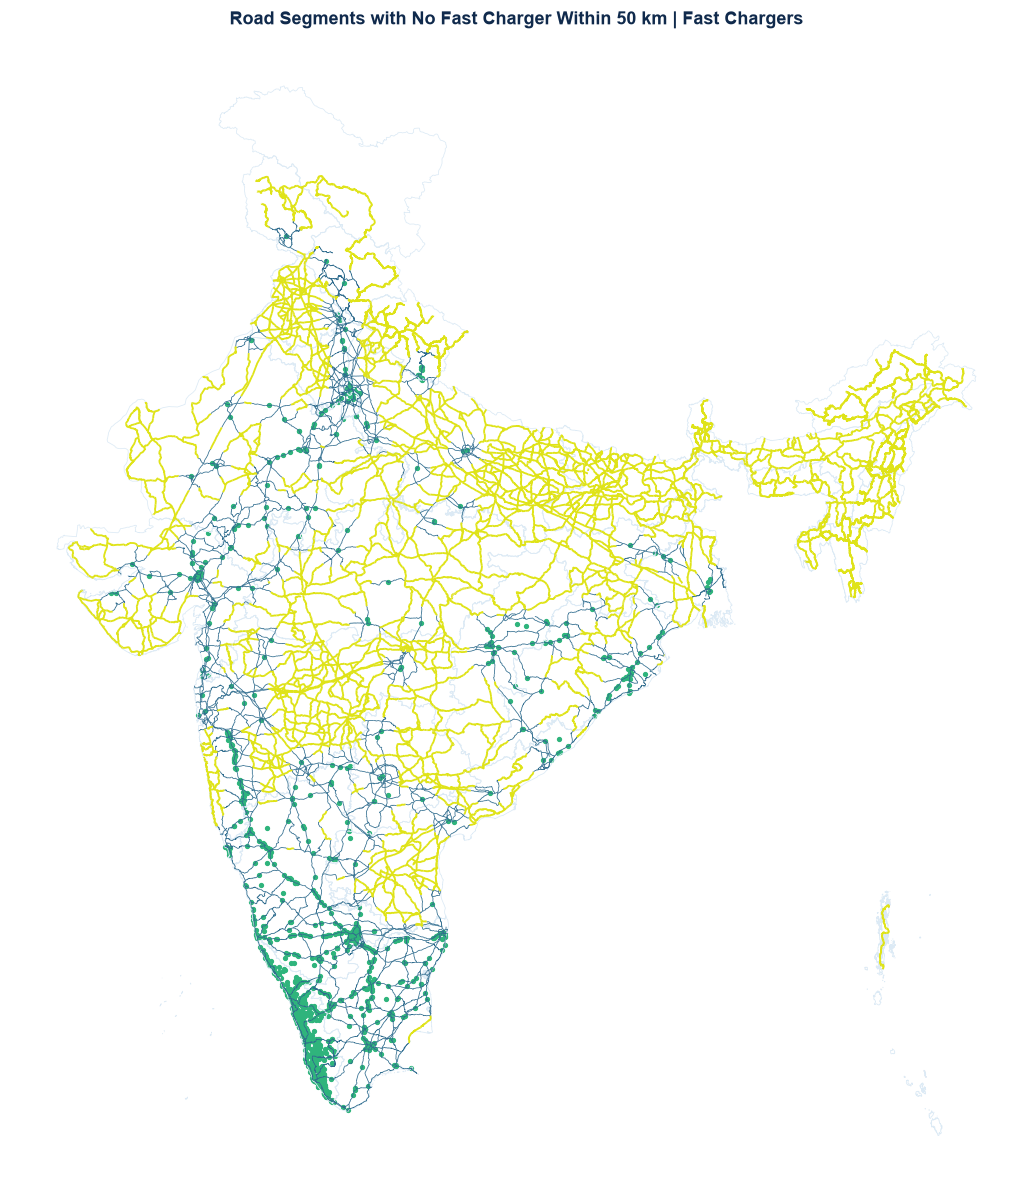

In [175]:
# National EV highway gap map using Viridis

fig, ax = plt.subplots(figsize=(10, 11))

states_m.boundary.plot(ax=ax, color="#DCEAF5", linewidth=0.5)

# Road segments with nearby fast chargers
seg_nat[~seg_nat["is_gap"]].plot(
    ax=ax, color=plt.cm.viridis(0.35), linewidth=0.5
)

# Road segments with charging gaps
seg_nat[seg_nat["is_gap"]].plot(
    ax=ax, color=plt.cm.viridis(0.95), linewidth=1.2
)

# Fast charging stations
chargers_gdf[chargers_gdf["is_fast"]].plot(
    ax=ax, color=plt.cm.viridis(0.65), markersize=6
)

ax.set_title(
    f"Road Segments with No Fast Charger Within {GAP_KM} km | Fast Chargers",
    color="#102A4C"
)
ax.axis("off")

plt.tight_layout()
finish("08_national_gap_map")


# Prepare the six target highways as continuous lines

In [176]:
hw6 = hw_all[hw_all["road_name"].isin(TARGET_HIGHWAYS)]

raw_km = highways_gdf[highways_gdf["road_name"].isin(TARGET_HIGHWAYS)].groupby("road_name")["length_km"].sum()

rows = []
for road, group in hw6.groupby("road_name"):
    union_geom = unary_union(group.geometry.values)
    merged = union_geom if union_geom.geom_type == "LineString" else linemerge(union_geom)
    parts = [merged] if merged.geom_type == "LineString" else list(merged.geoms)
    for cid, line in enumerate(parts, start=1):
        rows.append({"road_name": road, "component_id": cid, "length_km": line.length / 1000, "geometry": line})

In [177]:
components = gpd.GeoDataFrame(rows, geometry="geometry", crs=METRIC_CRS)
components["keep"] = components["length_km"] >= MIN_COMPONENT_KM
road_parts = components[components["keep"]].copy()

length_check = pd.DataFrame({
    "raw_summed_km": raw_km,
    "unique_km": components.groupby("road_name")["length_km"].sum(),
    "kept_km": road_parts.groupby("road_name")["length_km"].sum(),
    "pieces_kept": road_parts.groupby("road_name").size()
}).round(1)

display(length_check)

,raw_summed_km,unique_km,kept_km,pieces_kept
road_name,,,,
NH-16,2175.1,1750.0,1711.8,25
NH-44,3794.3,3591.6,3558.1,34
NH-48,2602.8,2555.0,2542.5,24
NH-52,2232.4,2232.4,2228.7,23
NH-544,330.6,330.6,330.6,2
NH-66,1952.2,1711.6,1646.0,43


# Identify chargers within 5 km of each highway

In [178]:
buffers = road_parts.dissolve(by="road_name")
buffers["geometry"] = buffers.geometry.buffer(CORRIDOR_KM * 1000)
buffers = buffers.reset_index()[["road_name", "geometry"]]

corridor_chargers = gpd.sjoin(chargers_gdf, buffers, predicate="within", how="inner").drop(columns="index_right")
fast_corridor_chargers = corridor_chargers[corridor_chargers["is_fast"]].copy()

In [179]:
cc_stats = corridor_chargers.groupby("road_name").agg(
    all_chargers=("ID", "nunique"),
    fast_chargers=("is_fast", "sum"),
    avg_power_kw=("max_power_kw", "mean")
).round(1)

print("Unique chargers near any target highway:", corridor_chargers["ID"].nunique())
display(cc_stats)

Unique chargers near any target highway: 878


,all_chargers,fast_chargers,avg_power_kw
road_name,,,
NH-16,114,38,19.9
NH-44,213,186,57.4
NH-48,216,191,52.2
NH-52,20,19,48.9
NH-544,109,101,43.5
NH-66,259,243,44.0


# Divide the six highways into approximately 25 km segments

In [180]:
seg_rows = []
for _, row in road_parts.iterrows():
    length = row.geometry.length
    n_segments = max(1, int(round(length / (SEG_KM * 1000))))
    step = length / n_segments
    for i in range(n_segments):
        seg = substring(row.geometry, i * step, (i + 1) * step)
        mid = seg.interpolate(0.5, normalized=True)
        seg_rows.append({
            "road_name": row["road_name"],
            "component_id": row["component_id"],
            "segment_id": i + 1,
            "start_km": i * step / 1000,
            "end_km": (i + 1) * step / 1000,
            "length_km": step / 1000,
            "mid_x": mid.x,
            "mid_y": mid.y,
            "geometry": seg
        })

In [181]:
segments = gpd.GeoDataFrame(seg_rows, geometry="geometry", crs=METRIC_CRS)
print("Segments:", len(segments))

display(
    segments.groupby("road_name")["length_km"].agg(["count", "sum", "min", "max"]).round(1)
)

Segments: 519


,count,sum,min,max
road_name,,,,
NH-16,77,1711.8,5.3,31.1
NH-44,149,3558.1,5.1,32.5
NH-48,105,2542.5,5.4,33.3
NH-52,90,2228.7,6.1,36.0
NH-544,14,330.6,23.5,23.7
NH-66,84,1646.0,5.2,31.2


# Detect charging gaps on the six target highways

In [182]:
def gap_distance(segs, fast_pts):
    """
    Compute distance (km) from each segment midpoint to the nearest fast charger
    that sits on the same highway.
    """
    out = pd.Series(np.inf, index=segs.index)
    for road, idx in segs.groupby("road_name").groups.items():
        pts = fast_pts[fast_pts["road_name"] == road]
        if pts.empty:
            continue
        tree = cKDTree(np.c_[pts.geometry.x, pts.geometry.y])
        d, _ = tree.query(segs.loc[idx, ["mid_x", "mid_y"]].values)
        out.loc[idx] = d / 1000
    return out

In [183]:
# Compute nearest fast charger distance
segments["nearest_fast_km"] = gap_distance(segments, fast_corridor_chargers)
segments["is_gap"] = segments["nearest_fast_km"] > GAP_KM
segments["gap_km"] = segments["length_km"] * segments["is_gap"]

In [184]:
# Assign states to segments
mids6 = gpd.GeoDataFrame(
    segments[["road_name"]],
    geometry=gpd.points_from_xy(segments["mid_x"], segments["mid_y"]),
    crs=METRIC_CRS)

In [185]:
j6 = gpd.sjoin_nearest(mids6, st_small, how="left")
j6 = j6[~j6.index.duplicated()]
segments["state_key"] = j6["state_geo"]
segments["state"] = segments["state_key"].map(key2name)

In [186]:
print("Gap segments:", int(segments["is_gap"].sum()), "of", len(segments),
      "| segments without state:", segments["state"].isna().sum())

Gap segments: 161 of 519 | segments without state: 0


# Research question 5 — How reliable is fast-charging coverage on each highway?

In [187]:
def longest_gap_km(g):
    best = 0
    for _, comp in g.sort_values("start_km").groupby("component_id"):
        cur = 0
        for gap, l in zip(comp["is_gap"], comp["length_km"]):
            cur = cur + l if gap else 0
            best = max(best, cur)
    return best

In [188]:
# Build scorecard
sc = (
    segments.groupby("road_name")
    .apply(lambda g: pd.Series({
        "road_km": g["length_km"].sum(),
        "segments": len(g),
        "gap_segments": int(g["is_gap"].sum()),
        "gap_km": g["gap_km"].sum(),
        "longest_gap_km": longest_gap_km(g)
    }))
    .reset_index()   # <-- ensures road_name is a column
)

In [189]:
# Coverage %
sc["covered_pct"] = 100 * (1 - sc["gap_km"] / sc["road_km"])

In [190]:
# Merge with corridor charger stats
sc = sc.merge(cc_stats.reset_index(), on="road_name", how="left")

In [191]:
# Fill missing values
sc[["all_chargers", "fast_chargers"]] = sc[["all_chargers", "fast_chargers"]].fillna(0)

In [192]:
# Derived metrics
sc["fast_per_100km"] = sc["fast_chargers"] / sc["road_km"] * 100
sc["rating"] = pd.cut(sc["covered_pct"], [-1, 70, 90, 101], labels=["Poor", "Patchy", "Reliable"])

In [193]:
# Sort and clean index
sc = sc.sort_values("covered_pct", ascending=False).reset_index(drop=True).round(1)

In [194]:
# Display
display(sc[["road_name", "road_km", "fast_chargers", "fast_per_100km",
            "covered_pct", "gap_km", "longest_gap_km", "rating"]])
# Export clean CSV
sc.to_csv(OUT / "tables" / "highway_scorecard.csv", index=False)

,road_name,road_km,fast_chargers,fast_per_100km,covered_pct,gap_km,longest_gap_km,rating
0,NH-544,330.6,101,30.6,100.0,0.0,0.0,Reliable
1,NH-48,2542.5,191,7.5,97.7,58.2,27.1,Reliable
2,NH-66,1646.0,243,14.8,70.1,491.8,376.1,Patchy
3,NH-16,1711.8,38,2.2,64.4,609.0,126.2,Poor
4,NH-44,3558.1,186,5.2,56.0,1566.8,426.6,Poor
5,NH-52,2228.7,19,0.9,50.0,1114.7,173.4,Poor


#  Visualize highway reliability results

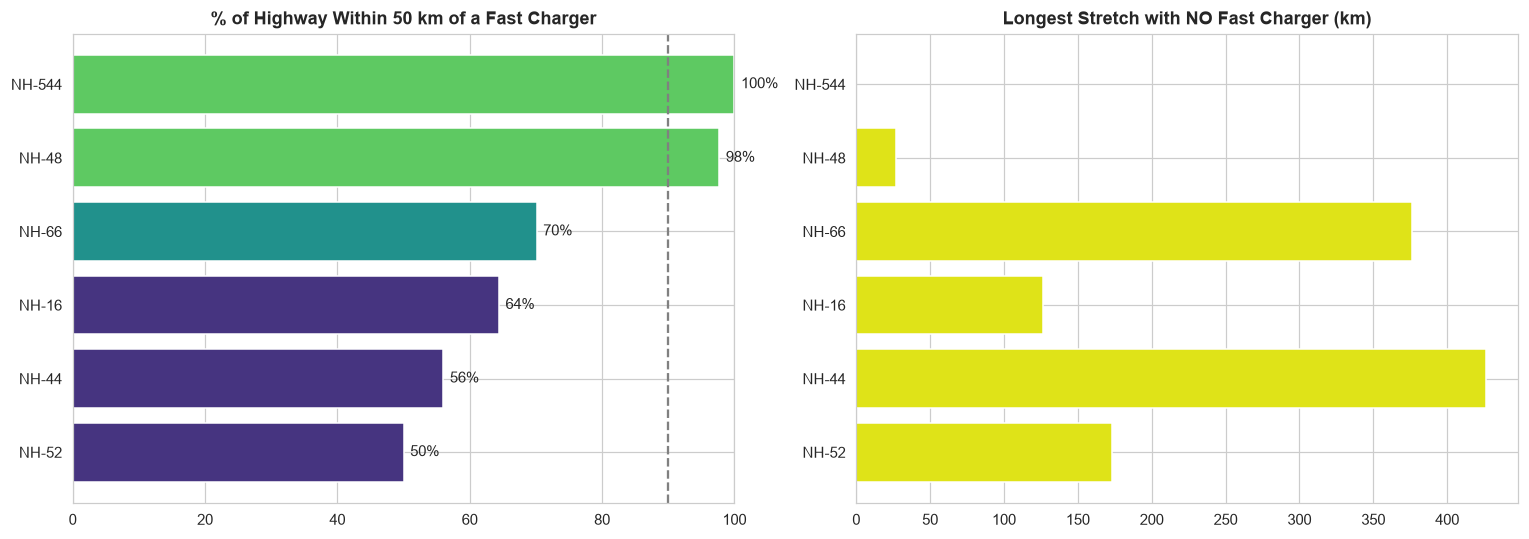

In [195]:
# Highway scorecard using Viridis

color_map = {
    "Reliable": 0.75,
    "Patchy": 0.50,
    "Poor": 0.15
}

colors = [
    plt.cm.viridis(color_map.get(str(rating), 0.30))
    for rating in sc["rating"]
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Coverage %
axes[0].barh(sc["road_name"], sc["covered_pct"], color=colors)
axes[0].axvline(90, ls="--", color="grey")
axes[0].set_xlim(0, 100)

for y, v in enumerate(sc["covered_pct"]):
    axes[0].text(v + 1, y, f"{v:.0f}%", va="center")

axes[0].invert_yaxis()
axes[0].set_title(f"% of Highway Within {GAP_KM} km of a Fast Charger")

# Longest gaps
axes[1].barh(
    sc["road_name"],
    sc["longest_gap_km"],
    color=plt.cm.viridis(0.95)
)
axes[1].invert_yaxis()
axes[1].set_title("Longest Stretch with NO Fast Charger (km)")

plt.tight_layout()
finish("09_highway_scorecard")

# Map highway coverage and charging gaps

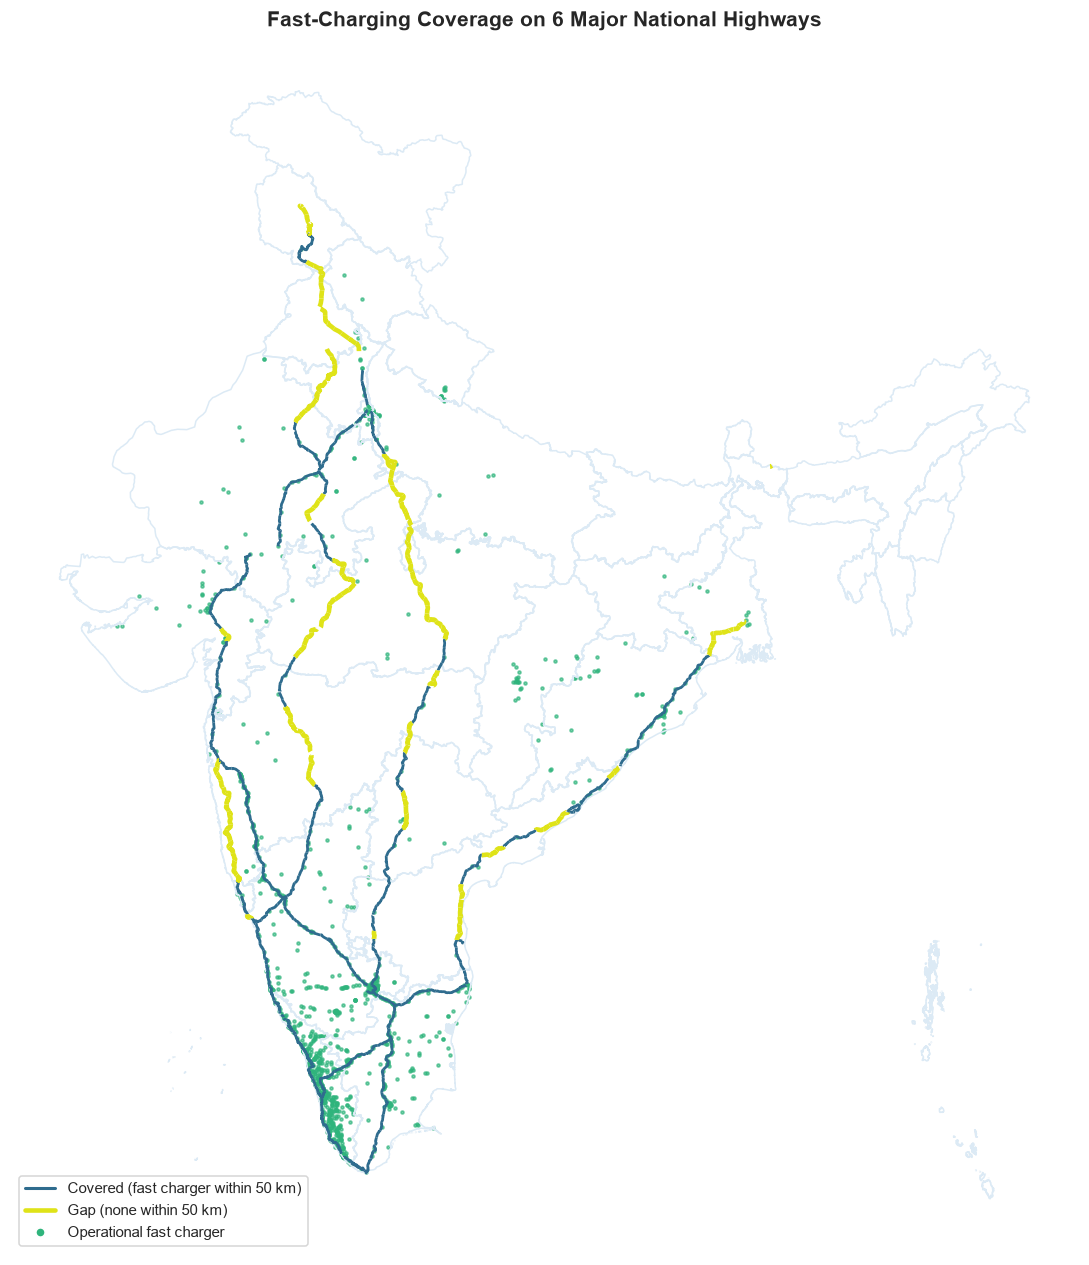

In [196]:
# Map highway coverage and charging gaps using Viridis

fast_all = chargers_gdf[chargers_gdf["is_fast"]]

covered_color = plt.cm.viridis(0.35)
gap_color = plt.cm.viridis(0.95)
charger_color = plt.cm.viridis(0.65)

fig, ax = plt.subplots(figsize=(10, 12))

states_m.boundary.plot(ax=ax, color="#DCEAF5", linewidth=1.0)
segments[~segments["is_gap"]].plot(ax=ax, color=covered_color, linewidth=1.8)
segments[segments["is_gap"]].plot(ax=ax, color=gap_color, linewidth=3)
fast_all.plot(ax=ax, color=charger_color, markersize=4, alpha=0.65)

# Legend
ax.legend(handles=[
    Line2D([0], [0], color=covered_color, lw=2,
           label=f"Covered (fast charger within {GAP_KM} km)"),
    Line2D([0], [0], color=gap_color, lw=3,
           label=f"Gap (none within {GAP_KM} km)"),
    Line2D([0], [0], marker="o", color="w",
           markerfacecolor=charger_color, markersize=6,
           label="Operational fast charger")
], loc="lower left")

ax.set_axis_off()
ax.set_title("Fast-Charging Coverage on 6 Major National Highways", fontsize=14)

plt.tight_layout()
finish("10_gap_map_6_highways")

# Create one coverage map per highway

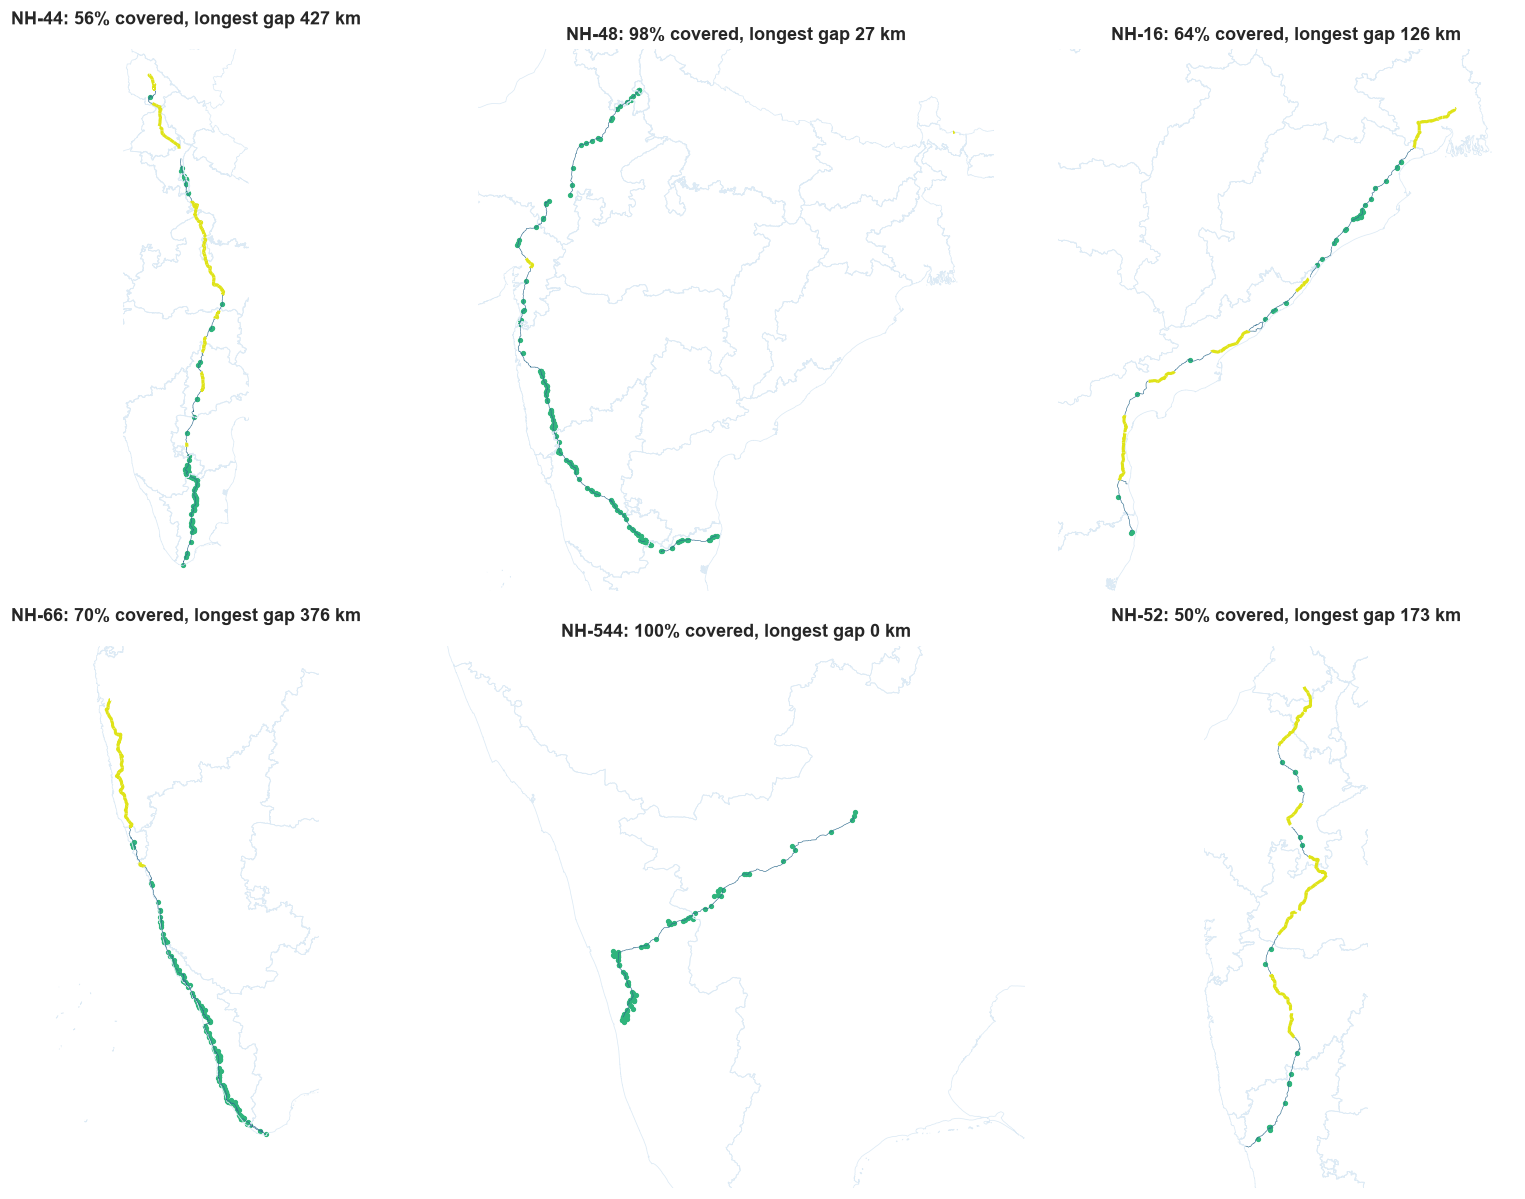

In [197]:
# Individual highway gap maps using Viridis

fig, axes = plt.subplots(2, 3, figsize=(16, 11))

covered_color = plt.cm.viridis(0.35)
gap_color = plt.cm.viridis(0.95)
charger_color = plt.cm.viridis(0.65)

for ax, road in zip(axes.ravel(), TARGET_HIGHWAYS):
    s = segments[segments["road_name"] == road].copy()

    # Remove missing and empty geometries
    s = s[s.geometry.notna() & ~s.geometry.is_empty]

    if s.empty:
        ax.set_title(f"{road}: No valid segments")
        ax.set_axis_off()
        continue

    # Calculate map boundaries
    bounds = s.total_bounds

    if not np.isfinite(bounds).all():
        ax.set_title(f"{road}: Invalid map bounds")
        ax.set_axis_off()
        continue

    states_m.boundary.plot(ax=ax, color="#DCEAF5", linewidth=0.5)

    s[~s["is_gap"]].plot(
        ax=ax, color=covered_color, linewidth=0.4
    )

    if s["is_gap"].any():
        s[s["is_gap"]].plot(
            ax=ax, color=gap_color, linewidth=2
        )

    chargers = fast_corridor_chargers[
        fast_corridor_chargers["road_name"] == road
    ]

    if not chargers.empty:
        chargers.plot(
            ax=ax, color=charger_color, markersize=6
        )

    minx, miny, maxx, maxy = bounds
    pad = 150_000

    ax.set_xlim(minx - pad, maxx + pad)
    ax.set_ylim(miny - pad, maxy + pad)
    ax.set_axis_off()

    row = sc[sc["road_name"] == road]

    if not row.empty:
        row = row.iloc[0]
        ax.set_title(
            f"{road}: {row['covered_pct']:.0f}% covered, "
            f"longest gap {row['longest_gap_km']:.0f} km"
        )
    else:
        ax.set_title(road)

plt.tight_layout()
finish("11_gap_map_per_highway")

#  Research question 6 — Which states should be prioritized for new fast chargers?

In [198]:
state_gap6 = segments.groupby("state").agg(
    highway_km=("length_km", "sum"),
    gap_segments=("is_gap", "sum"),
    gap_km=("gap_km", "sum")
).reset_index()

In [199]:
state_gap6["gap_pct"] = state_gap6["gap_km"] / state_gap6["highway_km"] * 100

priority = (
    state_gap6.merge(master[["state", "ev_demand", "n_fast"]], on="state", how="left")
    .sort_values("gap_km", ascending=False)
    .round(1)
)


In [200]:
display(priority.reset_index(drop=True).head(12))
priority.to_csv(OUT / "tables" / "state_priority_6_highways.csv", index=False)

,state,highway_km,gap_segments,gap_km,gap_pct,ev_demand,n_fast
0,Maharashtra,1833.8,37,891.2,48.6,1170473,75.0
1,Madhya Pradesh,895.4,33,795.9,88.9,513003,11.0
2,Andhra Pradesh,1309.4,18,453.3,34.6,278501,14.0
3,Punjab,335.8,13,335.8,100.0,181928,2.0
4,Rajasthan,1306.9,13,327.8,25.1,569096,46.0
5,Uttar Pradesh,314.7,10,248.9,79.1,1815492,20.0
6,Jammu and Kashmir,360.0,11,186.4,51.8,54215,1.0
7,West Bengal,186.1,9,186.1,100.0,341644,7.0
8,Telangana,497.8,7,175.2,35.2,357920,10.0
9,Haryana,398.6,7,165.2,41.4,191304,26.0


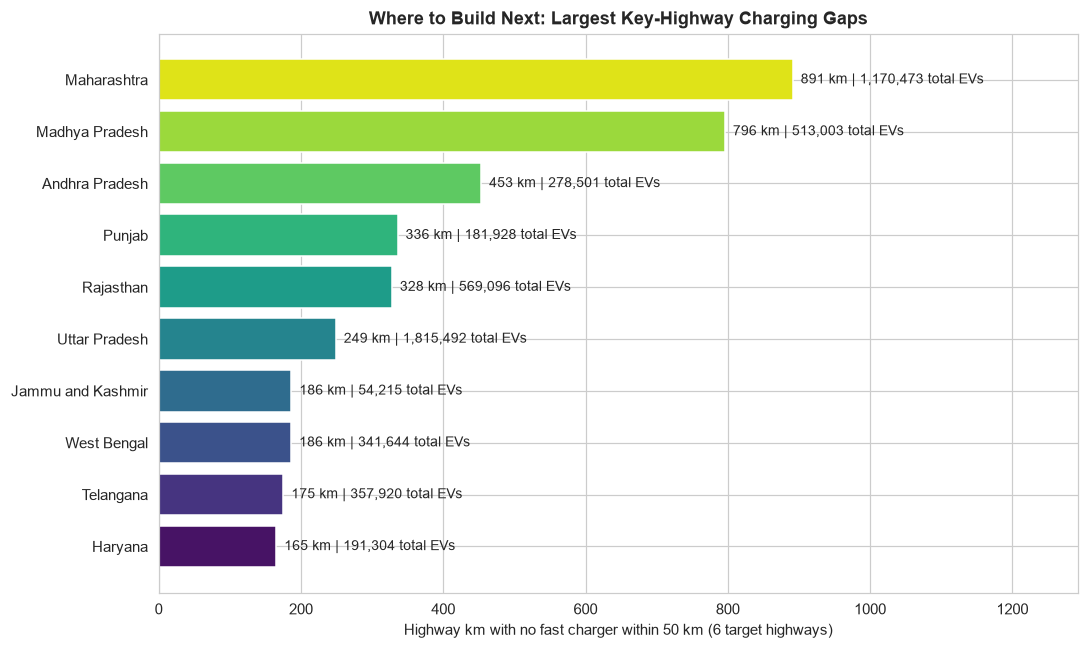

In [201]:
# Plot top 10 uncovered states using Viridis
p = priority[priority["gap_km"] > 0].head(10).iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 6))

colors = plt.cm.viridis(np.linspace(0.05, 0.95, len(p)))

ax.barh(p["state"], p["gap_km"], color=colors)

for y, (g, e) in enumerate(zip(p["gap_km"], p["ev_demand"])):
    ax.text(g, y, f"  {g:,.0f} km | {e:,.0f} total EVs",
            va="center", fontsize=9)

ax.set_xlabel(f"Highway km with no fast charger within {GAP_KM} km (6 target highways)")
ax.set_title("Where to Build Next: Largest Key-Highway Charging Gaps")
ax.set_xlim(0, p["gap_km"].max() * 1.45)

plt.tight_layout()
finish("12_state_priority_6_highways")

# Research question 7 — How sensitive are results to the gap-distance rule?

In [202]:
res = {}
for thr in [25, 50, 75, 100]:
    gap = (segments["nearest_fast_km"] > thr) * segments["length_km"]
    res[f"{thr} km"] = 100 * (1 - gap.groupby(segments["road_name"]).sum() /
                              segments.groupby("road_name")["length_km"].sum())

sens = pd.DataFrame(res).round(1)
display(sens)

,25 km,50 km,75 km,100 km
road_name,,,,
NH-16,43.6,64.4,77.5,86.4
NH-44,39.7,56.0,65.9,74.4
NH-48,81.6,97.7,99.7,99.7
NH-52,31.4,50.0,59.0,68.0
NH-544,100.0,100.0,100.0,100.0
NH-66,65.8,70.1,74.6,76.1


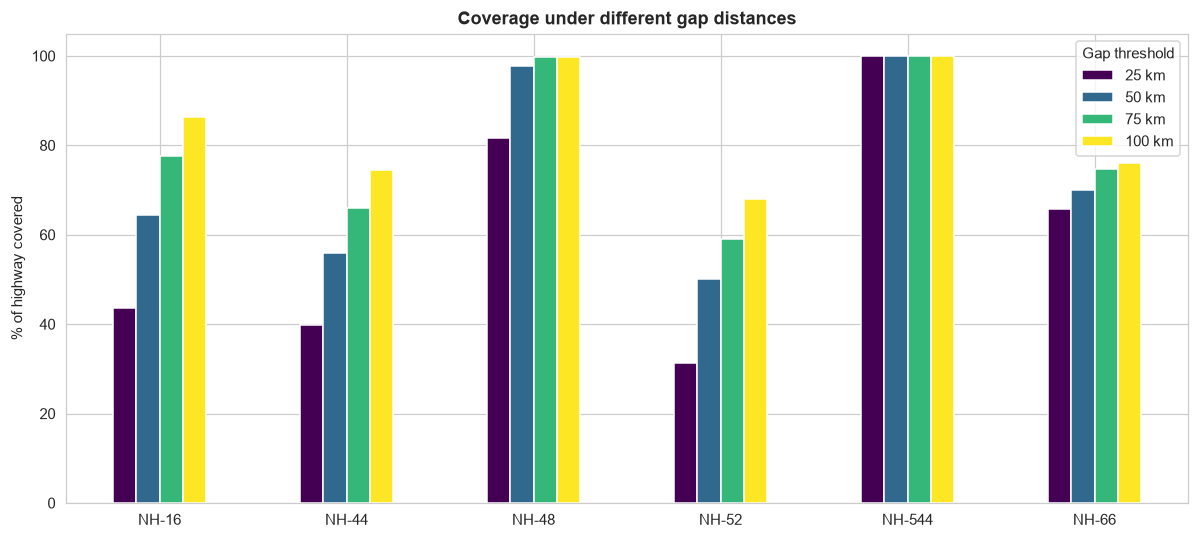

In [203]:
sens.plot(kind="bar", figsize=(11, 5), colormap="viridis")
plt.ylabel("% of highway covered")
plt.xlabel("")
plt.title("Coverage under different gap distances")
plt.xticks(rotation=0)
plt.legend(title="Gap threshold")
finish("13_sensitivity_gap_distance")

# Q How does the fast-charger definition affect results?

In [204]:
def coverage_by_road(mask):
    pts = corridor_chargers[mask]
    d = gap_distance(segments, pts)
    gap = (d > GAP_KM) * segments["length_km"]
    return 100 * (1 - gap.groupby(segments["road_name"]).sum() /
                  segments.groupby("road_name")["length_km"].sum())

In [205]:
defs = {
    "power >= 22 kW": corridor_chargers["max_power_kw"] >= 22,
    "power >= 25 kW": corridor_chargers["max_power_kw"] >= 25,
    "power >= 50 kW": corridor_chargers["max_power_kw"] >= 50,
    "dataset flag": corridor_chargers["has_fast_charging"].astype(bool)
}

In [206]:
sens2 = pd.DataFrame({name: coverage_by_road(m) for name, m in defs.items()}).round(1)
display(sens2)

,power >= 22 kW,power >= 25 kW,power >= 50 kW,dataset flag
road_name,,,,
NH-16,64.4,64.4,33.3,24.2
NH-44,56.0,56.0,48.0,56.0
NH-48,97.7,97.7,81.7,95.6
NH-52,50.0,50.0,28.9,50.0
NH-544,100.0,100.0,100.0,100.0
NH-66,70.1,70.1,70.1,70.1


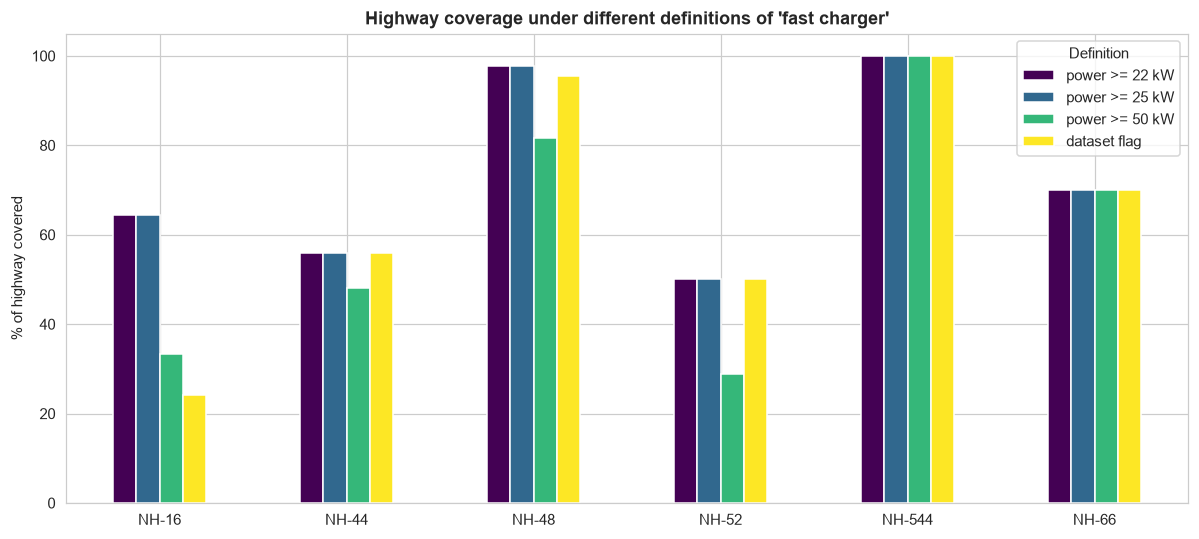

In [207]:
sens2.plot(kind="bar", figsize=(11, 5), colormap="viridis")
plt.ylabel("% of highway covered")
plt.xlabel("")
plt.xticks(rotation=0)
plt.title("Highway coverage under different definitions of 'fast charger'")
plt.legend(title="Definition")
finish("14_sensitivity_fast_definition")

In [208]:
# RATING UNDER EACH DEFINITION 
def rate(s):
    
    return pd.cut(s, [-1, 70, 90, 101], labels=["Poor", "Patchy", "Reliable"]).astype(str)

rating_tbl = sens2.apply(rate)
core = ["power >= 25 kW", "dataset flag"]                      # the two realistic definitions
rating_tbl["verdict"] = np.where(rating_tbl[core].nunique(axis=1) == 1,
                                 "Stable rating", "Depends on definition")
rating_tbl["coverage_range_%"] = (sens2.min(axis=1).round(0).astype(int).astype(str) + " - "
                                  + sens2.max(axis=1).round(0).astype(int).astype(str))
display(rating_tbl)
rating_tbl.to_csv(OUT / "tables" / "highway_rating_by_definition.csv")

,power >= 22 kW,power >= 25 kW,power >= 50 kW,dataset flag,verdict,coverage_range_%
road_name,,,,,,
NH-16,Poor,Poor,Poor,Poor,Stable rating,24 - 64
NH-44,Poor,Poor,Poor,Poor,Stable rating,48 - 56
NH-48,Reliable,Reliable,Patchy,Reliable,Stable rating,82 - 98
NH-52,Poor,Poor,Poor,Poor,Stable rating,29 - 50
NH-544,Reliable,Reliable,Reliable,Reliable,Stable rating,100 - 100
NH-66,Patchy,Patchy,Patchy,Patchy,Stable rating,70 - 70


# Add highway metrics to the state master table

In [209]:
hwy = seg_nat.groupby("state_key").agg(
    hwy_km=("seg_km", "sum"),
    gap_km=("gap_km", "sum")
).reset_index()

corr = chargers_gdf.groupby("state_geo")["on_corridor"].sum().rename("n_on_corridor").reset_index()
corr = corr.rename(columns={"state_geo": "state_key"})

In [210]:
master = (
    master.drop(columns=["hwy_km", "gap_km", "n_on_corridor"], errors="ignore")
    .merge(hwy, on="state_key", how="left")
    .merge(corr, on="state_key", how="left")
)

master[["hwy_km", "gap_km", "n_on_corridor"]] = master[["hwy_km", "gap_km", "n_on_corridor"]].fillna(0)
master["fast_per_1000_hwy_km"] = np.where(master["hwy_km"] > 0, master["n_fast"] / master["hwy_km"] * 1000, np.nan)
master["pct_hwy_gap"] = np.where(master["hwy_km"] > 0, master["gap_km"] / master["hwy_km"] * 100, np.nan)

In [211]:
print("States with no highway in the data:", master.loc[master["hwy_km"] == 0, "state"].tolist())
display(master.sort_values("ev_total", ascending=False).reset_index(drop=True)
.head(10)[
    ["state", "ev_total", "n_chargers", "n_fast", "hwy_km", "gap_km", "pct_hwy_gap"]
])

States with no highway in the data: ['Lakshadweep', 'Chandigarh']


,state,ev_total,n_chargers,n_fast,hwy_km,gap_km,pct_hwy_gap
0,Uttar Pradesh,1815492,29.0,20.0,15135.034570,11546.006248,76.286620
1,Maharashtra,1170473,83.0,75.0,20421.393780,12933.476949,63.332979
2,Karnataka,912484,376.0,323.0,8133.700981,205.194170,2.522765
3,Tamil Nadu,708760,212.0,181.0,7767.455336,154.961173,1.995006
4,Rajasthan,569096,47.0,46.0,11810.818158,5324.898092,45.084921
5,Bihar,560438,1.0,0.0,6739.936650,6739.936650,100.000000
6,Delhi,515897,34.0,17.0,244.067473,0.000000,0.000000
7,Madhya Pradesh,513003,13.0,11.0,11169.005208,8781.682204,78.625464
8,Kerala,433492,587.0,544.0,2245.258984,0.000000,0.000000
9,Gujarat,415842,67.0,36.0,8850.324493,3869.317529,43.719499


# Explore top states and correlations

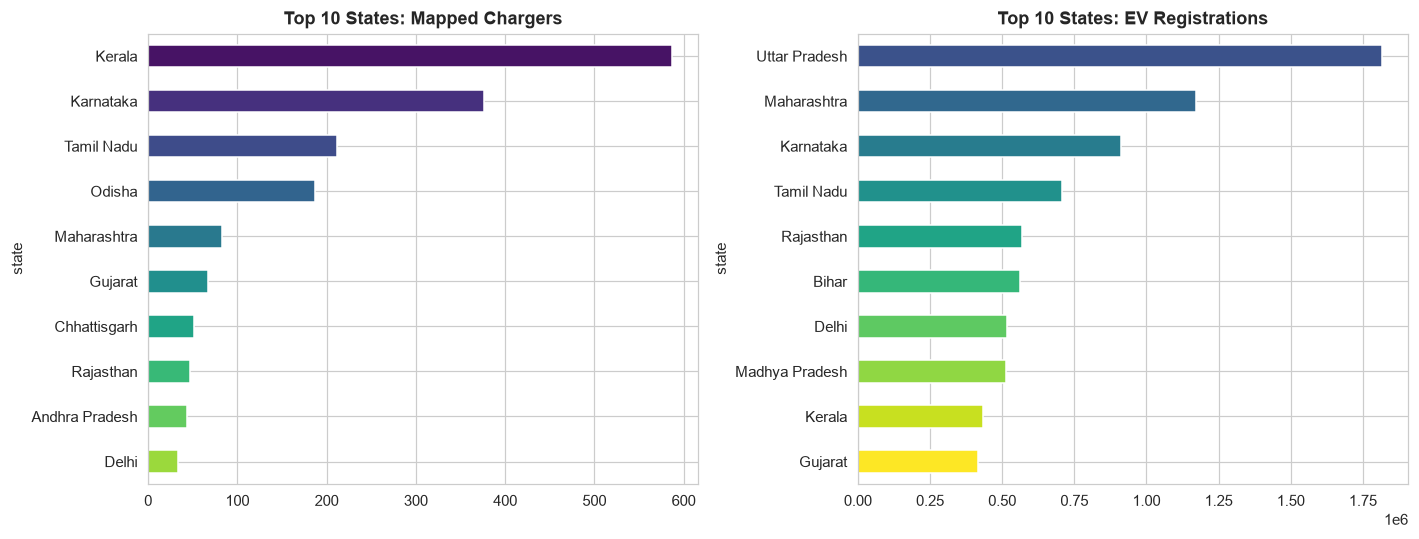

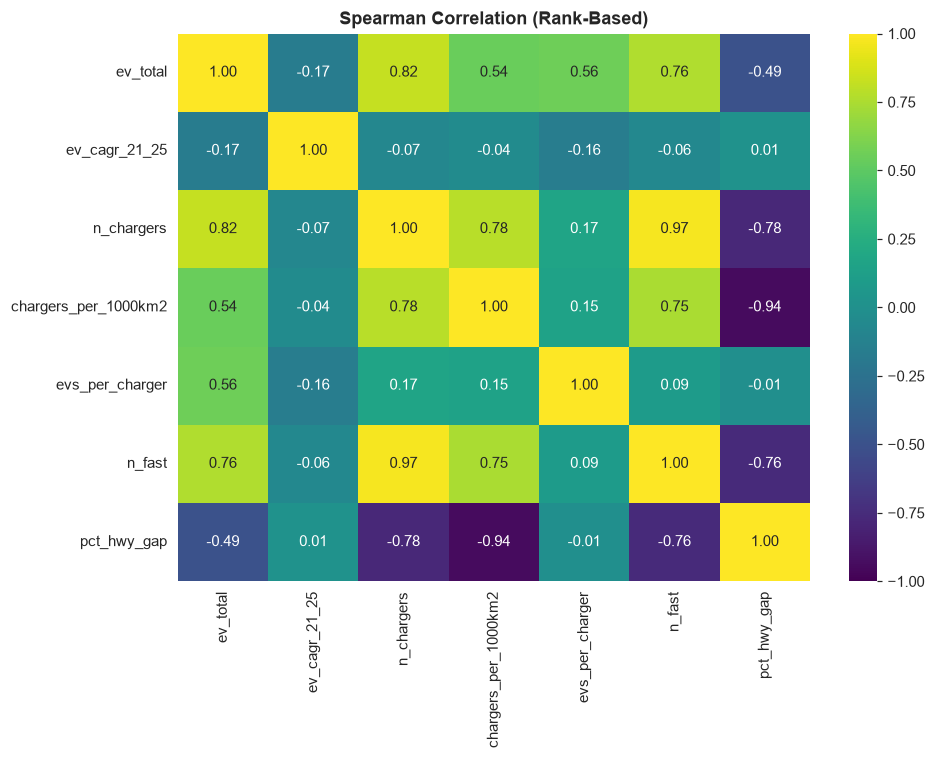

In [212]:
# Top states: chargers vs EV registrations
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# Top 10 states by mapped chargers - purple to green
chargers_top = master.nlargest(10, "n_chargers")
colors1 = plt.cm.viridis(np.linspace(0.05, 0.85, len(chargers_top)))

chargers_top.plot.barh(
    x="state", y="n_chargers", ax=ax[0],
    legend=False, color=colors1
)
ax[0].set_title("Top 10 States: Mapped Chargers")
ax[0].invert_yaxis()

# Top 10 states by EV registrations - blue to yellow
evs_top = master.nlargest(10, "ev_total")
colors2 = plt.cm.viridis(np.linspace(0.25, 1.0, len(evs_top)))

evs_top.plot.barh(
    x="state", y="ev_total", ax=ax[1],
    legend=False, color=colors2
)
ax[1].set_title("Top 10 States: EV Registrations")
ax[1].invert_yaxis()

plt.tight_layout()
finish("15_top_states_chargers_vs_evs")


# Spearman correlation heatmap using Viridis
num_cols = [
    "ev_total", "ev_cagr_21_25", "n_chargers",
    "chargers_per_1000km2", "evs_per_charger",
    "n_fast", "pct_hwy_gap"
]

plt.figure(figsize=(9, 7))

sns.heatmap(
    master[num_cols].corr(method="spearman"),
    annot=True,
    fmt=".2f",
    cmap="viridis",
    vmin=-1,
    vmax=1
)

plt.title("Spearman Correlation (Rank-Based)")
plt.tight_layout()
finish("16_spearman_heatmap")

# Calculate the state gap score (EV Desert Index)

In [213]:
def minmax(s):
    s = s.astype(float)
    return (s - s.min()) / (s.max() - s.min()) if s.max() > s.min() else s * 0

g = master.copy()
g["pct_hwy_gap"] = g["pct_hwy_gap"].fillna(g["pct_hwy_gap"].median())

g["n_demand"] = minmax(np.log1p(g["evs_per_charger"]))          # more EVs per charger = worse
g["n_hwygap"] = minmax(g["pct_hwy_gap"])                       # more uncovered highway = worse
g["n_density"] = minmax(np.log1p(g["chargers_per_1000km2"]))   # sparse chargers = worse

W = {"n_demand": 0.40, "n_hwygap": 0.35, "n_density": 0.25}

g[list(W)] = g[list(W)].replace([np.inf, -np.inf], np.nan).fillna(0)
g["gap_score"] = 100 * sum(g[k] * w for k, w in W.items())
g["gap_rank"] = g["gap_score"].rank(ascending=False, method="min").astype(int)
g["gap_class"] = pd.qcut(g["gap_score"], q=3, labels=["Low gap", "Medium gap", "High gap"])

master = g

display(master.sort_values("gap_score", ascending=False)[
    ["state", "ev_total", "n_chargers", "evs_per_charger", "pct_hwy_gap", "gap_score", "gap_class"]
].reset_index(drop=True).head(15))


,state,ev_total,n_chargers,evs_per_charger,pct_hwy_gap,gap_score,gap_class
0,Bihar,560438,1.0,560438.000000,100.000000,75.085616,High gap
1,Chandigarh,27419,1.0,27419.000000,72.201918,70.914021,High gap
2,Assam,384300,2.0,192150.000000,100.000000,70.850359,High gap
3,Tripura,45221,0.0,45221.000000,100.000000,64.762825,High gap
4,Punjab,181928,2.0,90964.000000,85.718567,62.917898,High gap
5,Uttar Pradesh,1815492,29.0,62603.172414,76.286620,58.703081,High gap
6,Madhya Pradesh,513003,13.0,39461.769231,78.625464,57.062435,High gap
7,West Bengal,341644,9.0,37960.444444,75.395582,56.249296,High gap
8,Jharkhand,139850,6.0,23308.333333,79.838222,55.597795,High gap
9,Manipur,4115,0.0,4115.000000,100.000000,55.015457,High gap


# Cluster states with K-means

In [214]:
X = StandardScaler().fit_transform(master[["n_demand", "n_hwygap", "n_density"]])
master["cluster"] = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(X)

prof = master.groupby("cluster")[["gap_score", "ev_total", "n_chargers"]].mean().round(1)
prof["states"] = master.groupby("cluster").size()
display(prof)

,gap_score,ev_total,n_chargers,states
cluster,,,,
0,52.4,408848.8,23.1,18
1,37.9,334214.2,156.4,9
2,44.5,1179.3,0.0,9


NameError: name 'adjust_text' is not defined

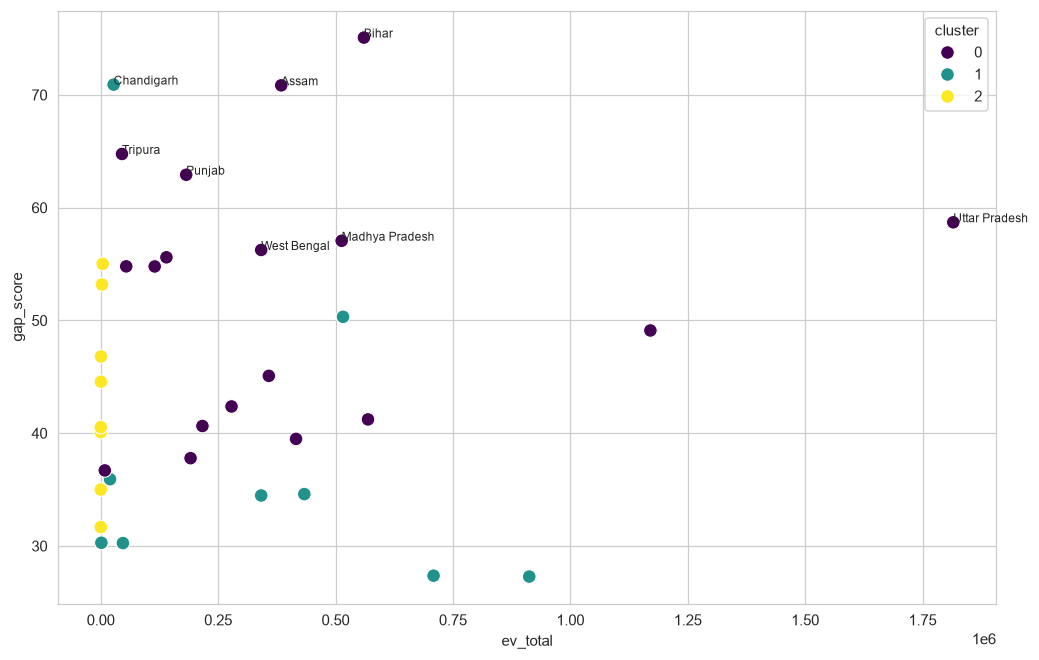

In [215]:
# State clusters using Viridis with non-overlapping labels
plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=master,
    x="ev_total",
    y="gap_score",
    hue="cluster",
    palette="viridis",
    s=80
)

# Label the top 8 states by gap score
top_states = master.nlargest(8, "gap_score")
texts = []

for _, r in top_states.iterrows():
    texts.append(
        plt.text(
            r["ev_total"],
            r["gap_score"],
            r["state"],
            fontsize=8
        )
    )

adjust_text(
    texts,
    x=top_states["ev_total"],
    y=top_states["gap_score"],
    expand=(1.3, 1.5),
    arrowprops=dict(arrowstyle="-", color="grey", lw=0.6)
)

plt.xscale("log")
plt.title("State Clusters: EV Volume vs Gap Score")
plt.tight_layout()
finish("17_state_clusters")

# Test the stability of weighting choices

In [ ]:
scen = {
    "base 0.40/0.35/0.25": (0.40, 0.35, 0.25),
    "equal weights": (1/3, 1/3, 1/3),
    "demand-heavy": (0.6, 0.2, 0.2),
    "highway-heavy": (0.2, 0.6, 0.2),
    "density-heavy": (0.2, 0.2, 0.6)
}

base_top = set(master.nlargest(10, "gap_score")["state"])
base_rank = master["gap_score"].rank(ascending=False)

In [ ]:
rows = []
for name, (a, b, c_) in scen.items():
    s = 100 * (a * master["n_demand"] + b * master["n_hwygap"] + c_ * master["n_density"])
    rows.append({
        "scenario": name,
        "top10_overlap": len(base_top & set(master.assign(s=s).nlargest(10, "s")["state"])),
        "rank_correlation": round(base_rank.corr(s.rank(ascending=False), method="spearman"), 3)
    })

In [ ]:
# Alternative demand definition: cars+buses per fast charger
alt_d = minmax(np.log1p(master["evs_per_fast_charger"]))
s = 100 * (0.40 * alt_d + 0.35 * master["n_hwygap"] + 0.25 * master["n_density"])
rows.append({
    "scenario": "demand = cars+buses per fast charger",
    "top10_overlap": len(base_top & set(master.assign(s=s).nlargest(10, "s")["state"])),
    "rank_correlation": round(base_rank.corr(s.rank(ascending=False), method="spearman"), 3)
})

display(pd.DataFrame(rows))

,scenario,top10_overlap,rank_correlation
0,base 0.40/0.35/0.25,10,1.000
1,equal weights,8,0.964
2,demand-heavy,8,0.885
3,highway-heavy,6,0.816
4,density-heavy,5,0.446
5,demand = cars+buses per fast charger,9,0.990


# Q Identify where the overall gap is biggest

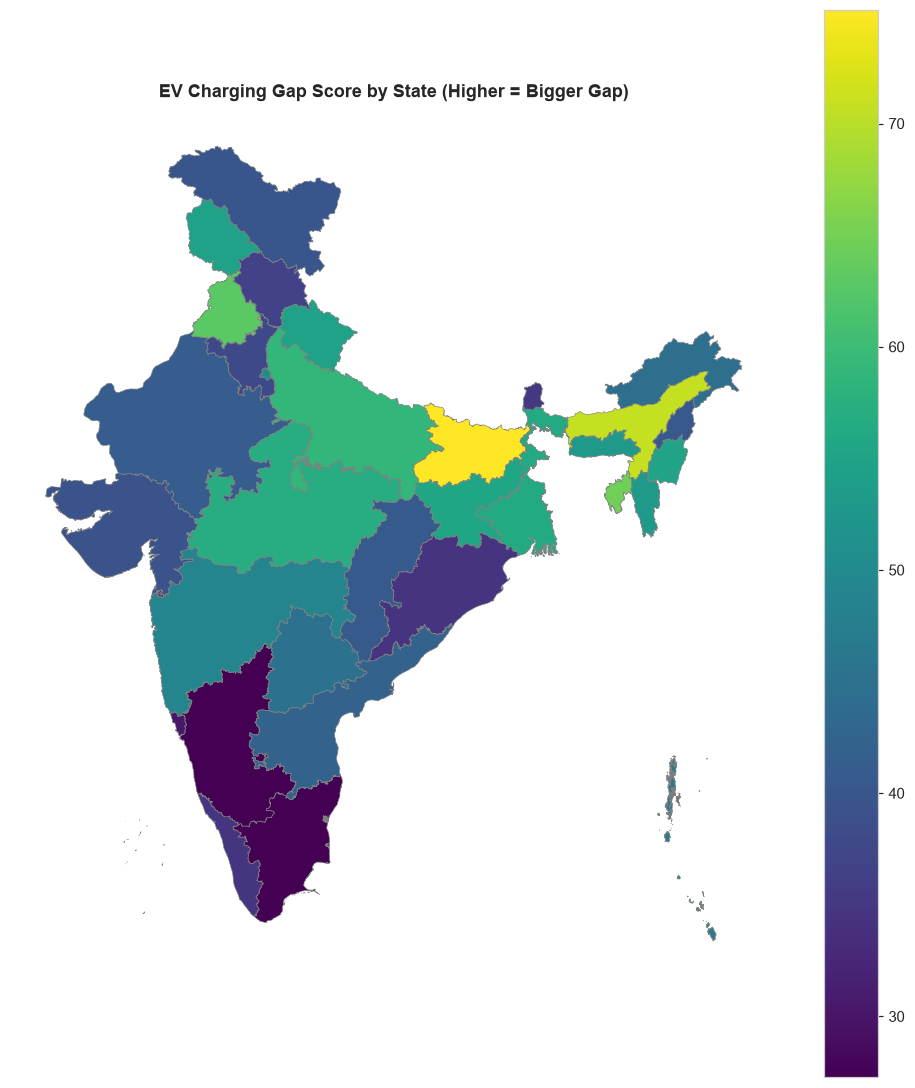

In [ ]:
# EV charging gap score map using Viridis
choro = states_m.merge(
    master[["state_key", "gap_score", "gap_class"]],
    on="state_key",
    how="left"
)

fig, ax = plt.subplots(figsize=(9, 10))

choro.plot(
    column="gap_score",
    cmap="viridis",
    legend=True,
    edgecolor="grey",
    linewidth=0.4,
    missing_kwds={"color": "lightgrey"},
    ax=ax
)

ax.set_title("EV Charging Gap Score by State (Higher = Bigger Gap)")
ax.axis("off")

plt.tight_layout()
finish("18_gap_score_map")

# Rank the top 10 states by gap score

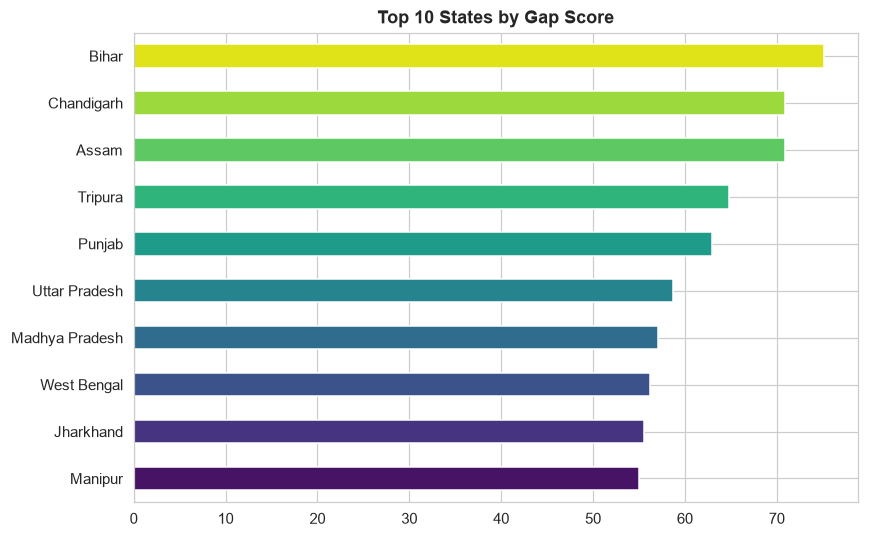

In [ ]:
# Top 10 states by gap score using different Viridis colors
top10_gap = master.nlargest(10, "gap_score").iloc[::-1]

colors = plt.cm.viridis(np.linspace(0.05, 0.95, len(top10_gap)))

top10_gap.plot.barh(
    x="state",
    y="gap_score",
    figsize=(8, 5),
    legend=False,
    color=colors
)

plt.title("Top 10 States by Gap Score")
plt.ylabel("")
plt.tight_layout()
finish("19_top10_gap_score")

# Compare state gap scores with key-highway gaps

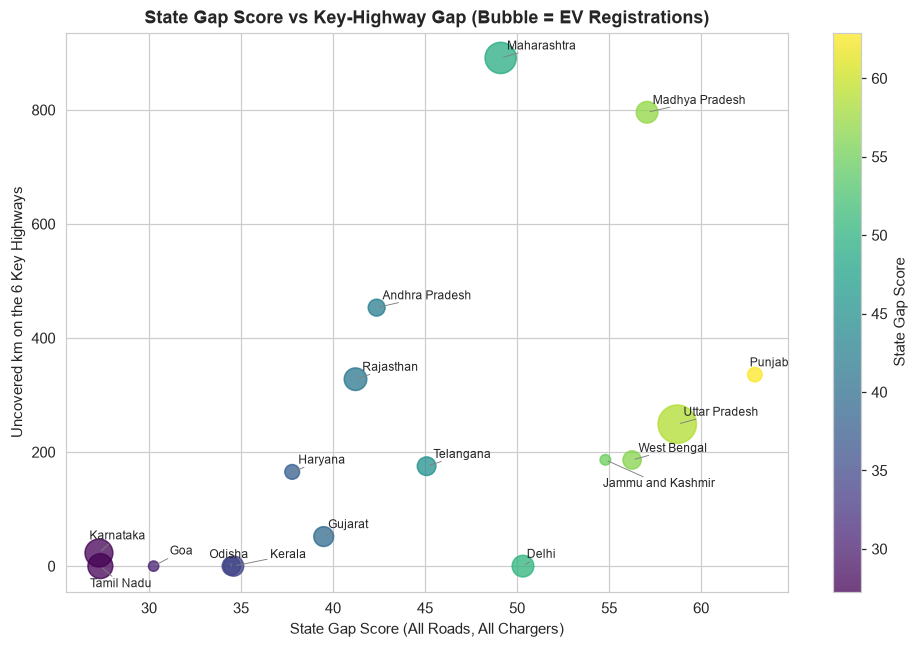

In [ ]:
# State gap score vs highway corridor gap using Viridis
x = master[["state", "gap_score", "ev_total"]].merge(
    priority[["state", "gap_km"]], on="state", how="inner"
)

plt.figure(figsize=(9, 6))

plt.scatter(
    x["gap_score"],
    x["gap_km"],
    s=x["ev_total"] / x["ev_total"].max() * 600 + 30,
    c=x["gap_score"],
    cmap="viridis",
    alpha=0.75
)

texts = []

for _, r in x.iterrows():
    texts.append(
        plt.text(
            r["gap_score"],
            r["gap_km"],
            r["state"],
            fontsize=8
        )
    )

adjust_text(
    texts,
    x=x["gap_score"],
    y=x["gap_km"],
    expand=(1.3, 1.5),
    force_text=(0.8, 1.2),
    force_static=(0.5, 0.8),
    arrowprops=dict(
        arrowstyle="-",
        color="grey",
        lw=0.6
    )
)
plt.colorbar(label="State Gap Score")
plt.xlabel("State Gap Score (All Roads, All Chargers)")
plt.ylabel("Uncovered km on the 6 Key Highways")
plt.title("State Gap Score vs Key-Highway Gap (Bubble = EV Registrations)")

plt.tight_layout()
finish("20_score_vs_corridor_gap")

# KEY FINDINGS

In [ ]:
top5 = master.nlargest(5, "gap_score")["state"].tolist()
best, worst = sc.iloc[0], sc.iloc[-1]
longest = sc.sort_values("longest_gap_km", ascending=False).iloc[0]
nat_gap = seg_nat["gap_km"].sum()
deserts = master[master["ev_demand"] >= MIN_DEMAND].nlargest(3, "evs_per_fast_charger")["state"].tolist()
zero = master.loc[master["n_chargers"] == 0, "state"].tolist()

In [ ]:
print("KEY FINDINGS")
print(f"1. EV fleet: {int(ev_registration['Total'].sum()):,} total registrations.")
print(f"2. Mapped operational chargers: {len(chargers_gdf):,}; fast (>= {FAST_KW} kW): {int(chargers_gdf['is_fast'].sum()):,}.")
print(f"3. {nat_gap:,.0f} km of the road network "
      f"({nat_gap/seg_nat['seg_km'].sum():.0%}) has no fast charger within {GAP_KM} km.")
print(f"4. Best-covered key highway: {best['road_name']} ({best['covered_pct']:.0f}%). Worst: {worst['road_name']} ({worst['covered_pct']:.0f}%).")
print(f"5. Longest key-highway stretch with no fast charger: {longest['longest_gap_km']:.0f} km on {longest['road_name']}.")
print(f"6. Largest key-highway gap: {priority.iloc[0]['state']} ({priority.iloc[0]['gap_km']:.0f} km uncovered).")
print(f"7. Highest overall gap scores: {', '.join(top5)}.")
print(f"8. Biggest EV deserts (total EV registrations per fast charger): {', '.join(deserts)}.")
print(f"9. States with zero mapped chargers: {', '.join(zero) or 'none'}.")
print(f"10. {chargers_gdf['on_corridor'].mean():.0%} of operational chargers are within {CORRIDOR_KM} km of a mapped highway.")


KEY FINDINGS
1. EV fleet: 10,377,820 total registrations.
2. Mapped operational chargers: 1,823; fast (>= 25 kW): 1,421.
3. 98,551 km of the road network (60%) has no fast charger within 50 km.
4. Best-covered key highway: NH-544 (100%). Worst: NH-52 (50%).
5. Longest key-highway stretch with no fast charger: 427 km on NH-44.
6. Largest key-highway gap: Maharashtra (891 km uncovered).
7. Highest overall gap scores: Bihar, Chandigarh, Assam, Tripura, Punjab.
8. Biggest EV deserts (total EV registrations per fast charger): Bihar, Assam, Uttar Pradesh.
9. States with zero mapped chargers: Lakshadweep, Ladakh, Sikkim, Nagaland, Arunachal Pradesh, Meghalaya, Tripura, Mizoram, Manipur, Andaman and Nicobar Islands.
10. 86% of operational chargers are within 5 km of a mapped highway.


In [ ]:
# Export tables
master.drop(columns=["cluster"], errors="ignore").to_csv(OUT / "tables" / "state_gap_master.csv", index=False)
seg_nat.to_crs(4326).to_file(OUT / "tables" / "national_segments_gap.geojson", driver="GeoJSON")
segments.drop(columns=["mid_x", "mid_y"]).to_crs(4326).to_file(OUT / "tables" / "segments_6_highways_gap.geojson", driver="GeoJSON")
chargers_gdf.to_crs(4326).drop(columns=["date_created", "date_last_verified"], errors="ignore") \
    .to_file(OUT / "tables" / "chargers_clean.geojson", driver="GeoJSON")

print("\nSaved outputs to:", OUT.resolve())


Saved outputs to: C:\Users\INBA\Desktop\OneDrive - ELCOT\Inba\Anudip\Project\EV_Highway_Corridor_Reliability_Gap_Analysis\Visualization
